# Session 5 : le TP et les exercices expliqués pas à pas

**Projet vision : activations et initialisation** (MSA-DATB09-03, Neural Networks & Deep Learning Foundations)

Ce notebook contient **toutes les réponses** de la session 5, expliquées :

- les **20 exercices du TP05** (`TP05_vision_project.ipynb`), avec le code complété et les `assert` d'origine, qui doivent afficher `Exercise validated!` ;
- la **question de prédiction** de la slide 8 ;
- les **3 exercices papier** du cours (slides 13, 15 et 23), calculés à la main puis vérifiés en Python.

On suit l'ordre de la séance : on construit un classifieur de vêtements, on le rend plus profond, il casse, on comprend pourquoi, et on le répare.

| Bloc | Contenu | Slides | Ce qu'on apprend |
|---|---|---|---|
| **Partie A** (TP, exercices 1 à 8) | la baseline 784-128-10 sur FashionMNIST | 4 à 7 | tout le pipeline PyTorch sur de vraies images |
| **Prédiction** | et avec 6 couches cachées ? | 8 et 9 | plus profond n'est pas forcément mieux |
| **Exercice du cours 1** | à quelle vitesse le gradient disparaît | 10 à 13 | le **vanishing gradient** : $\sigma' \le 1/4$ |
| **Exercice du cours 2** | une chaîne ReLU, forward et backward | 14 à 16 | la ReLU laisse passer le gradient... ou le coupe |
| **Partie B** (TP, exercices 9 à 12) | le réseau sigmoïde profond | 9 à 12 | mesurer le gradient de chaque couche |
| **Partie C** (TP, exercices 13 à 16) | ReLU et les autres activations | 14 à 18 | quelle activation où, les ReLU mortes |
| **Exercice du cours 3** | les poids initiaux d'une couche 784-256 | 19 à 23 | l'argument de variance, Xavier et He |
| **Partie D** (TP, exercices 17 à 19) | l'initialisation | 19 à 22 | le signal à travers 10 couches |
| **Pour aller plus loin** (TP, exercice 20) | dépasser 88 % | 25 | ReLU + He + Adam |

Pour ne pas confondre : « **Exercice TP n** » renvoie au notebook TP05, « **Exercice du cours n** » aux slides.

**Livrables demandés** : la précision de test et l'erreur la plus fréquente (partie A), le tableau des activations (exercice TP 15) et le graphique des écarts-types (exercice TP 18). Ils sont récapitulés à la fin.

**Comment le lire.** Pour chaque exercice :

1. 📖 **Le cours** : la notion, la formule et d'où elle vient.
2. ✍️ **Le raisonnement**, ou le calcul à la main pour les exercices papier.
3. 💻 **Le code** : la solution entre `### START CODE HERE ###` et `### END CODE HERE ###`, suivie des `assert` du TP.
4. 💡 **Ce qu'on observe** : comment lire le résultat.

**Pour l'exécuter** : Google Colab (Fichier > Importer un notebook) ou en local avec `torch`, `torchvision`, `scikit-learn` et `matplotlib`. Les images (30 Mo) sont téléchargées une seule fois dans `./data`. Pas besoin de GPU : tout tourne en quelques minutes sur un CPU. Exécute les cellules **dans l'ordre** (Shift + Entrée). Les chiffres cités dans le texte viennent de notre exécution : chez toi, ils peuvent varier un peu (autre machine, autre version de PyTorch).

## 0. Mise en place

### Les imports

| Import | À quoi il sert |
|---|---|
| `torch`, `torch.nn` | les tenseurs, autograd et les couches (`nn.Linear`, `nn.ReLU`...) |
| `TensorDataset`, `DataLoader` | découper les données en mini-batchs (session 4) |
| `torchvision.datasets` | télécharge FashionMNIST |
| `confusion_matrix` (scikit-learn) | compte, pour chaque vraie classe, combien d'images sont prédites dans chaque classe |
| `numpy`, `matplotlib` | tableaux et graphiques |

Les constantes du TP : `N_TRAIN = 50 000` images d'entraînement, `EPOCHS_A = 10` époques pour la baseline, `EPOCHS = 5` pour chaque expérience des parties B à D, des batchs de `BATCH_SIZE = 128` et un pas d'apprentissage `LR = 0.2`. `FAST_RUN = True` (variable d'environnement `FAST_RUN=1`) réduit tout pour un test rapide : laisse-le à `False`.

In [1]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
from sklearn.metrics import confusion_matrix

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: smaller data and fewer epochs for a quick check
DATA_DIR = os.environ.get("DATA_DIR", "./data")
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"

N_TRAIN = 30_000 if FAST_RUN else 50_000    # training images used
EPOCHS_A = 4 if FAST_RUN else 10            # epochs for the Part A baseline
EPOCHS = 3 if FAST_RUN else 5               # epochs for each experiment of Parts B to D
BATCH_SIZE = 128
LR = 0.2                                    # SGD learning rate of Parts A to C
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("device:", device, "| FAST_RUN:", FAST_RUN)

device: cpu | FAST_RUN: False


### Les fonctions utilitaires (celles du TP04)

`evaluate`, `train_one_epoch` et `fit` sont les fonctions que tu as écrites au TP04. Rappel de ce qu'elles font :

- `train_one_epoch` : une **époque** = un passage sur toutes les images d'entraînement, batch par batch. Pour chaque batch, les 5 étapes de la session 4 : **forward** (`logits = model(xb)`), **loss**, **remise à zéro des gradients** (`optimizer.zero_grad()`), **backward** (`loss.backward()`), **mise à jour** (`optimizer.step()`). Elle renvoie la loss moyenne de l'époque.
- `evaluate` : mode évaluation (`model.eval()`), **sans gradient** (`torch.no_grad()`). Elle renvoie la loss moyenne et la **précision** (accuracy) : la proportion d'images dont la classe de plus grand logit (`argmax`) est la bonne.
- `fit` : répète `train_one_epoch` puis `evaluate` sur la validation pendant `n_epochs` époques, et renvoie l'historique `{"train_loss": [...], "val_loss": [...], "val_acc": [...]}` (une valeur par époque).
- `show_images` : affiche quelques images avec un titre chacune.

Détail : `loss.item() * len(yb)` puis la division par `total`. La loss d'un batch est une **moyenne** sur ce batch ; on la remultiplie par la taille du batch pour obtenir une vraie moyenne sur toutes les images, même si le dernier batch est plus petit.

In [2]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history


def show_images(images, titles, n=10):
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 1.9))
    for ax, img, title in zip(axes, images[:n], titles[:n]):
        ax.imshow(img.reshape(28, 28).cpu(), cmap="gray_r")
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.show()

---
# Partie A : le projet, classer des vêtements (TP, exercices 1 à 8)

## 📖 Le jeu de données FashionMNIST (slide 4)

Zalando a publié en 2017 ce remplaçant du célèbre MNIST (chiffres manuscrits) : **70 000 photos de vêtements** en niveaux de gris, **28×28 pixels**, **10 classes** équilibrées.

| Indice | Classe | | Indice | Classe |
|---|---|---|---|---|
| 0 | T-shirt/top | | 5 | Sandal (sandale) |
| 1 | Trouser (pantalon) | | 6 | Shirt (chemise) |
| 2 | Pullover (pull) | | 7 | Sneaker (basket) |
| 3 | Dress (robe) | | 8 | Bag (sac) |
| 4 | Coat (manteau) | | 9 | Ankle boot (bottine) |

- 60 000 images d'entraînement (on en garde 10 000 pour la **validation**) et 10 000 images de **test** ;
- plus dur que les chiffres 8×8 de la session 4 : chemise, T-shirt, pull et manteau se ressemblent beaucoup à 28×28 pixels ;
- l'outil : exactement le réseau et la boucle d'entraînement de la session 4.

## Exercice TP 1 : charger FashionMNIST

> **Énoncé** : créer `X_full` (les pixels d'entraînement convertis en float32 et divisés par 255, donc dans $[0, 1]$), `y_full` (les étiquettes d'entraînement), puis la même chose pour le test : `X_test_raw` et `y_test`.

📖 **Ce qu'il faut savoir** (slide 6)

- `datasets.FashionMNIST(...)` renvoie un objet « dataset ». On pourrait le lire image par image (`train_set[i]`), mais c'est lent : chaque image passe par un objet PIL. Les attributs `.data` et `.targets` donnent **tout d'un coup** sous forme de tenseurs :
  - `.data` : des `uint8` (entiers de 0 à 255), forme `(60000, 28, 28)` ;
  - `.targets` : des `int64`, forme `(60000,)`, les numéros de classe de 0 à 9.
- `.float()` convertit en `float32`, le type des poids du réseau. `/ 255` ramène les pixels dans $[0, 1]$ (0 = le fond, 1 = le pixel le plus intense).
- Les étiquettes restent en `int64` : c'est ce qu'attend `nn.CrossEntropyLoss` (des numéros de classe, pas des vecteurs one-hot).

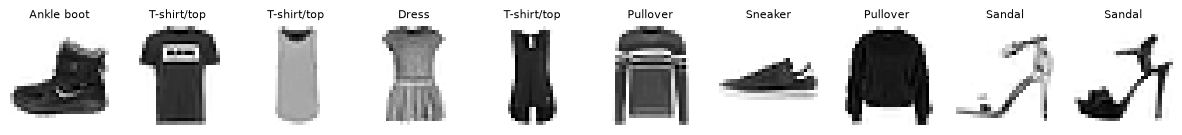

Exercise validated!


In [3]:
train_set = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
test_set = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)
### START CODE HERE ###
X_full = train_set.data.float() / 255      # (60000, 28, 28) : uint8 -> float32, pixels dans [0, 1]
y_full = train_set.targets                 # (60000,) int64 : les classes 0 à 9
X_test_raw = test_set.data.float() / 255   # (10000, 28, 28)
y_test = test_set.targets                  # (10000,)
### END CODE HERE ###

assert X_full.shape == (60000, 28, 28) and X_full.dtype == torch.float32, "X_full: float32, shape (60000, 28, 28)"
assert X_full.max().item() == 1.0 and X_full.min().item() == 0.0, "divide the pixels by 255"
assert y_full.shape == (60000,) and y_full.dtype == torch.int64, "y_full: int64 labels"
assert X_test_raw.shape == (10000, 28, 28) and y_test.shape == (10000,), "test set: 10 000 images"
show_images(X_full, [CLASSES[k] for k in y_full[:10]])
print("Exercise validated!")

## Exercice TP 2 : séparer et standardiser

> **Énoncé** : calculer `mean` et `std` (deux nombres Python, sur la partie entraînement **seulement**, avec `.item()`), puis `X_train`, `X_val` et `X_test` standardisés.

📖 **Pourquoi trois ensembles ?**

| Ensemble | Taille | Rôle |
|---|---|---|
| entraînement | 50 000 | le réseau **apprend** dessus (les gradients viennent de là) |
| validation | 10 000 | on **choisit** (architecture, nombre d'époques, pas d'apprentissage) en regardant la précision dessus |
| test | 10 000 | on **mesure une seule fois**, à la fin, la performance sur des images jamais vues |

La permutation aléatoire `perm` (graine fixée) mélange les 60 000 indices : les `N_TRAIN` premiers vont à l'entraînement, les 10 000 derniers (`perm[50000:]`) à la validation. Les deux parties ne se recouvrent pas.

📖 **La standardisation** (slide 5) :

$$x \leftarrow \frac{x - \mu}{s}$$

où $\mu$ est la moyenne et $s$ l'écart-type de **tous les pixels de toutes les images d'entraînement** (deux nombres en tout, pas un par pixel). Après ça, les entrées ont une moyenne 0 et un écart-type 1.

- **Pourquoi ?** Les pixels dans $[0, 1]$ sont tous positifs, avec une moyenne d'environ 0.29. Centrer et réduire donne des scores $z$ de taille raisonnable dès la première couche, ce qui facilite la descente de gradient. La partie D (initialisation) suppose justement des entrées de variance 1.
- **Pourquoi avec les statistiques de l'entraînement seulement ?** La validation et le test jouent le rôle d'images **futures**, inconnues au moment de l'entraînement. Calculer $\mu$ et $s$ avec elles ferait entrer une information du test dans le modèle : c'est une **fuite de données** (data leakage). On applique donc **la même** transformation ($\mu$ et $s$ de l'entraînement) aux trois ensembles.
- `.item()` transforme un tenseur qui contient une seule valeur en nombre Python (`float`).

In [4]:
perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
train_idx, val_idx = perm[:N_TRAIN], perm[50000:]
X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
### START CODE HERE ###
mean = X_train_raw.mean().item()           # UN nombre : la moyenne de tous les pixels d'entraînement
std = X_train_raw.std().item()             # UN nombre : leur écart-type
X_train = (X_train_raw - mean) / std       # moyenne 0, écart-type 1
X_val = (X_val_raw - mean) / std           # les MÊMES mean et std (ceux de l'entraînement)
X_test = (X_test_raw - mean) / std
### END CODE HERE ###

print(f"mean {mean:.4f}, std {std:.4f} | train {len(X_train)}, val {len(X_val)}, test {len(X_test)}")
assert abs(mean - X_train_raw.mean().item()) < 1e-6, "mean of the TRAINING part only"
assert abs(X_train.mean().item()) < 1e-3 and abs(X_train.std().item() - 1) < 1e-3, "X_train should have mean 0 and std 1"
assert abs(X_test.mean().item() - (X_test_raw.mean().item() - mean) / std) < 1e-4, "standardise the test set with the TRAINING mean and std"
print("Exercise validated!")

mean 0.2865, std 0.3532 | train 50000, val 10000, test 10000
Exercise validated!


💡 Le test standardisé n'a pas **exactement** une moyenne de 0 et un écart-type de 1 (ses images sont un peu différentes), et c'est normal : on lui applique la transformation de l'entraînement, comme on le ferait pour une nouvelle photo en production.

In [5]:
print(f"test standardisé : moyenne {X_test.mean().item():+.4f}, écart-type {X_test.std().item():.4f}")

test standardisé : moyenne +0.0011, écart-type 0.9977


## Exercice TP 3 : les DataLoaders

> **Énoncé** : créer `train_loader` (batchs de `BATCH_SIZE`, mélangé), `val_loader` et `test_loader` (batchs de 1000, non mélangés).

📖 **Ce qu'il faut savoir**

- `TensorDataset(X, y)` associe chaque image à son étiquette : `dataset[i]` renvoie `(X[i], y[i])`. Il fait ce que faisait ta classe `DigitsDataset` du TP04.
- `DataLoader(dataset, batch_size=..., shuffle=...)` découpe le dataset en **mini-batchs**. Une époque d'entraînement = $\lceil 50\,000 / 128 \rceil = 391$ batchs (le dernier ne contient que $50\,000 - 390 \times 128 = 80$ images).
- `shuffle=True` pour l'entraînement : un ordre différent à chaque époque, pour que les batchs ne soient pas toujours les mêmes et que l'ordre des données ne biaise pas les mises à jour.
- Pas de mélange pour la validation et le test (`shuffle=False` est la valeur par défaut) : on ne fait que mesurer, l'ordre ne change rien. Des batchs de 1000 vont plus vite et ne posent pas de problème de mémoire, puisqu'on ne stocke aucun gradient.

In [6]:
torch.manual_seed(0)
### START CODE HERE ###
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)      # shuffle=False par défaut
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=1000)
### END CODE HERE ###

xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))
assert xb.shape == (BATCH_SIZE, 28, 28) and yb.shape == (BATCH_SIZE,), "a batch: (128, 28, 28) images, (128,) labels"
assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler), "shuffle the training loader"
assert len(val_loader.dataset) == 10000 and len(test_loader.dataset) == 10000, "validation and test: 10 000 images each"
print("Exercise validated!")

one batch: (128, 28, 28) (128,) | batches per epoch: 391
Exercise validated!


## Exercice TP 4 : le réseau 784-128-10 à sigmoïde

> **Énoncé** : `model` = `nn.Flatten()`, une couche cachée de 128 neurones sigmoïdes (`nn.Linear` puis `nn.Sigmoid()`), une couche de sortie de 10 logits. Stocker le nombre de paramètres (calculé avec `numel`) dans `n_params`.

📖 **De l'image au vecteur** (slide 5)

Une couche dense (`nn.Linear`) prend un **vecteur**. `nn.Flatten()` met les 28 lignes de l'image bout à bout (elle n'a aucun paramètre) :

$$\underbrace{(B, 28, 28)}_{\text{batch d'images}} \xrightarrow{\ \texttt{nn.Flatten()}\ } \underbrace{(B, 784)}_{X} \xrightarrow{\ \text{784-128-10}\ } \underbrace{(B, 10)}_{\text{logits}}$$

⚠️ L'aplatissement jette la structure 2D : les pixels 0 et 28 sont voisins dans l'image (l'un au-dessus de l'autre), mais pour le réseau ce sont deux coordonnées quelconques. Les convolutions (session 7) régleront ce problème.

📖 **Pourquoi pas de softmax à la fin ?** La sortie est faite de 10 **logits** (des scores bruts). `nn.CrossEntropyLoss` applique elle-même la softmax puis le $-\log$ : en ajouter une dans le modèle la ferait appliquer deux fois.

📖 `nn.Sequential(couche1, couche2, ...)` enchaîne les modules : la sortie de l'un est l'entrée du suivant.

✍️ **Le nombre de paramètres à la main** (une couche $n_\text{in} \to n_\text{out}$ a $n_\text{out} \times n_\text{in}$ poids et $n_\text{out}$ biais) :

$$\underbrace{784 \times 128 + 128}_{100\,480} + \underbrace{128 \times 10 + 10}_{1\,290} = 101\,770 \text{ paramètres}$$

En code : `p.numel()` donne le nombre de valeurs d'un tenseur ; on additionne sur `model.parameters()` (les poids et les biais des deux `nn.Linear`).

In [7]:
torch.manual_seed(0)
### START CODE HERE ###
model = nn.Sequential(
    nn.Flatten(),              # (B, 28, 28) -> (B, 784)
    nn.Linear(784, 128),       # couche cachée : 784 x 128 poids + 128 biais
    nn.Sigmoid(),
    nn.Linear(128, 10),        # couche de sortie : 10 logits (la softmax est dans la loss)
).to(device)
n_params = sum(p.numel() for p in model.parameters())
### END CODE HERE ###

print(model)
assert model(xb.to(device)).shape == (BATCH_SIZE, 10), "the model must map (B, 28, 28) to (B, 10) logits"
assert n_params == 784 * 128 + 128 + 128 * 10 + 10, f"expected 101770 parameters, got {n_params}"
assert any(isinstance(m, nn.Sigmoid) for m in model), "use a sigmoid hidden layer (the network of Session 4)"
print("Exercise validated!")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


Exercise validated!


In [8]:
# Le détail, paramètre par paramètre (la forme d'un poids est (sortie, entrée), comme en session 3)
for name, p in model.named_parameters():
    print(f"{name:9s} forme {str(tuple(p.shape)):11s} {p.numel():>7d} valeurs")
print(f"{'total':28s} {n_params:>7d}")

1.weight  forme (128, 784)   100352 valeurs
1.bias    forme (128,)          128 valeurs
3.weight  forme (10, 128)      1280 valeurs
3.bias    forme (10,)            10 valeurs
total                         101770


## Exercice TP 5 : l'entraîner

> **Énoncé** : créer la loss (`nn.CrossEntropyLoss()`), l'optimiseur (`torch.optim.SGD` avec `lr=LR`), et entraîner `EPOCHS_A` époques avec `fit`. Stocker le dictionnaire renvoyé dans `history_a`.

📖 **La loss d'entropie croisée** (session 4). Pour une image de vraie classe $y$ et des logits $z_1, \dots, z_{10}$ :

$$p_k = \frac{e^{z_k}}{\sum_{j} e^{z_j}} \ \ \text{(softmax)} \qquad\qquad \mathcal{L} = -\log p_y$$

Si le réseau ne sait rien, il donne $p_k = 1/10$ à chaque classe et $\mathcal{L} = -\log(1/10) = \ln 10 \approx 2.30$. C'est la **loss du hasard** : retiens ce nombre, il reviendra en partie B.

📖 **SGD** : à chaque batch, $w \leftarrow w - \eta\, \nabla_w \mathcal{L}$ avec $\eta = 0.2$, pour **tous** les paramètres donnés par `model.parameters()`.

À quoi s'attendre (slide 9) : environ 82 % de précision de validation après 1 époque, 86 % après 5.

In [9]:
torch.manual_seed(0)
### START CODE HERE ###
loss_fn = nn.CrossEntropyLoss()                            # softmax + -log(probabilité de la bonne classe)
optimizer = torch.optim.SGD(model.parameters(), lr=LR)     # w <- w - 0.2 x gradient
history_a = fit(model, train_loader, val_loader, loss_fn, optimizer, EPOCHS_A)
### END CODE HERE ###

assert len(history_a["val_acc"]) == EPOCHS_A, "train for EPOCHS_A epochs"
assert history_a["train_loss"][-1] < history_a["train_loss"][0], "the training loss should decrease"
assert history_a["val_acc"][-1] > 0.8, f"validation accuracy should exceed 0.8, got {history_a['val_acc'][-1]:.3f}"
print("Exercise validated!")

epoch  1 | train loss 0.6858 | val loss 0.5002 | val acc 0.818


epoch  2 | train loss 0.4582 | val loss 0.4777 | val acc 0.825


epoch  3 | train loss 0.4152 | val loss 0.4270 | val acc 0.844


epoch  4 | train loss 0.3885 | val loss 0.4036 | val acc 0.852


epoch  5 | train loss 0.3694 | val loss 0.3924 | val acc 0.857


epoch  6 | train loss 0.3550 | val loss 0.3688 | val acc 0.866


epoch  7 | train loss 0.3418 | val loss 0.3694 | val acc 0.862


epoch  8 | train loss 0.3316 | val loss 0.3683 | val acc 0.867


epoch  9 | train loss 0.3215 | val loss 0.3981 | val acc 0.855


epoch 10 | train loss 0.3120 | val loss 0.3716 | val acc 0.864
Exercise validated!


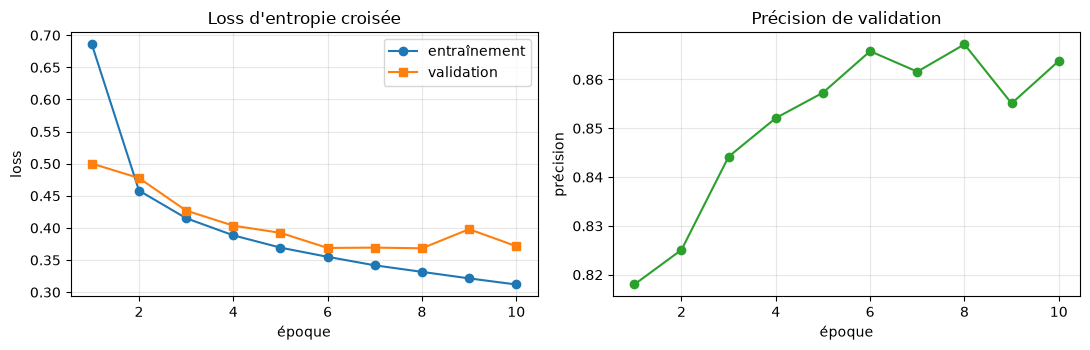

In [10]:
# Les courbes d'apprentissage de la baseline
ep_a = range(1, len(history_a["val_acc"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ep_a, history_a["train_loss"], "o-", label="entraînement")
axes[0].plot(ep_a, history_a["val_loss"], "s-", label="validation")
axes[0].set(xlabel="époque", ylabel="loss", title="Loss d'entropie croisée")
axes[0].legend()
axes[1].plot(ep_a, history_a["val_acc"], "o-", color="C2")
axes[1].set(xlabel="époque", ylabel="précision", title="Précision de validation")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

💡 **Ce qu'on observe.** La loss d'entraînement descend à chaque époque. La précision de validation monte vite (plus de 80 % dès la première époque) puis progresse lentement : ce petit réseau commence à plafonner. Les deux loss restent proches : pas encore de surapprentissage.

## Exercice TP 6 : la précision de test

> **Énoncé** : la baseline est choisie. La mesurer **une seule fois** sur le test : `test_loss, test_acc` avec `evaluate`.

📖 **Pourquoi une seule fois ?** Le test sert à estimer honnêtement la performance sur des images jamais vues. Si on essayait plusieurs modèles et qu'on gardait celui qui a le meilleur score de **test**, le test deviendrait une deuxième validation, et le chiffre annoncé serait trop optimiste. On **choisit** avec la validation, on **mesure** avec le test.

In [11]:
### START CODE HERE ###
test_loss, test_acc = evaluate(model, test_loader, loss_fn)    # une seule fois, à la fin
### END CODE HERE ###

print(f"test accuracy of the baseline: {test_acc:.3f}")
assert test_acc > 0.8, f"the baseline should exceed 0.8 on the test set, got {test_acc:.3f}"
print("Exercise validated!")

test accuracy of the baseline: 0.858
Exercise validated!


## Exercice TP 7 : la matrice de confusion

> **Énoncé** : calculer `pred` (la classe prédite de chaque image de test), la matrice `cm` avec `confusion_matrix`, puis l'erreur la plus fréquente `true_cls, pred_cls` : les indices $(i, j)$, avec $i \ne j$, de la plus grande case hors de la diagonale.

📖 **Lire une matrice de confusion**

- la **ligne** $i$ = les images dont la **vraie** classe est $i$ ;
- la **colonne** $j$ = les images **prédites** dans la classe $j$ ;
- `cm[i, j]` = le nombre d'images de vraie classe $i$ prédites $j$ ;
- la **diagonale** = les bonnes réponses : la somme de la diagonale divisée par 10 000 redonne la précision ;
- hors de la diagonale = les confusions. Chaque ligne somme à 1000 (le test contient 1000 images par classe).

✍️ **Les étapes du code**

1. `model.eval()` puis, dans `torch.no_grad()`, **un seul** forward sur les 10 000 images : `model(X_test)` donne des logits `(10000, 10)`, et `argmax(dim=1)` la colonne du plus grand logit de chaque ligne, c'est-à-dire la classe prédite.
2. `confusion_matrix(vraies, prédites)` de scikit-learn, sur des tableaux NumPy (`.numpy()`).
3. Pour trouver la plus grande erreur : on **copie** la matrice, on met sa diagonale à 0 (`np.fill_diagonal`), puis `off.argmax()` donne l'indice du maximum **dans le tableau aplati** (de 0 à 99). `np.unravel_index` le retransforme en (ligne, colonne). Exemple : l'indice aplati 60 d'une matrice 10×10 correspond à la ligne $60 \,//\, 10 = 6$ et à la colonne $60 \bmod 10 = 0$, soit (Shirt, T-shirt/top).

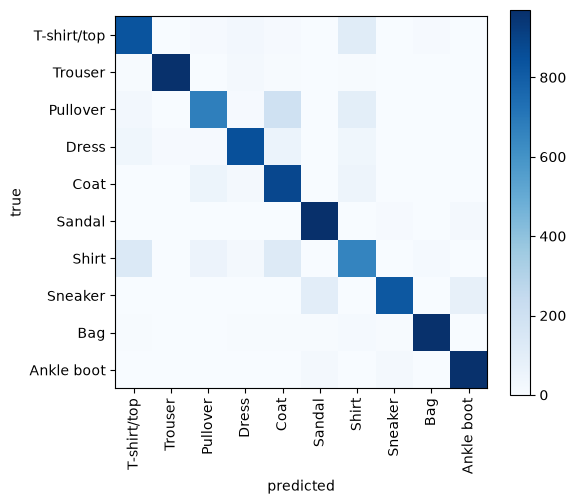

most frequent mistake: Pullover predicted as Coat (194 times)
Exercise validated!


In [12]:
### START CODE HERE ###
model.eval()                                               # mode évaluation
with torch.no_grad():                                      # pas besoin de gradient pour prédire
    pred = model(X_test.to(device)).argmax(dim=1).cpu()    # (10000,) : la classe du plus grand logit
cm = confusion_matrix(y_test.numpy(), pred.cpu().numpy())  # (10, 10) : lignes = vraies, colonnes = prédites
off = cm.copy()                                            # une copie, pour ne pas abîmer cm
np.fill_diagonal(off, 0)                                   # on efface les bonnes réponses
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)   # (ligne, colonne) du maximum
### END CODE HERE ###

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=90); plt.yticks(range(10), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")
assert cm.shape == (10, 10) and cm.sum() == 10000, "the matrix counts the 10 000 test images"
assert abs(np.trace(cm) / cm.sum() - test_acc) < 1e-6, "the diagonal should match the test accuracy"
assert true_cls != pred_cls and cm[true_cls, pred_cls] == off.max(), "find the largest entry outside the diagonal"
print("Exercise validated!")

In [13]:
# Pour aller un peu plus loin : la précision de chaque classe et les 5 confusions les plus fréquentes
par_classe = cm.diagonal() / cm.sum(axis=1)          # bonnes réponses / nombre d'images de la classe
print("Précision par classe (de la pire à la meilleure) :")
for k in np.argsort(par_classe):
    print(f"  {CLASSES[k]:12s} {par_classe[k]:.1%}")

print("\nLes 5 confusions les plus fréquentes :")
for flat in np.argsort(off, axis=None)[::-1][:5]:
    i, j = np.unravel_index(flat, off.shape)
    print(f"  vrai {CLASSES[i]:12s} -> prédit {CLASSES[j]:12s} {off[i, j]:4d} fois")

Précision par classe (de la pire à la meilleure) :
  Shirt        65.3%
  Pullover     67.4%
  Sneaker      82.2%
  T-shirt/top  83.5%
  Dress        84.9%
  Coat         88.2%
  Trouser      96.3%
  Bag          96.3%
  Ankle boot   96.4%
  Sandal       97.0%

Les 5 confusions les plus fréquentes :
  vrai Pullover     -> prédit Coat          194 fois
  vrai Shirt        -> prédit T-shirt/top   133 fois
  vrai Shirt        -> prédit Coat          122 fois
  vrai T-shirt/top  -> prédit Shirt         112 fois
  vrai Sneaker      -> prédit Sandal         99 fois


💡 **Ce qu'on observe.** Dans notre exécution, l'erreur la plus fréquente est **Pullover prédit Coat** : 194 pulls sur 1000 pris pour des manteaux. Les classes les plus difficiles sont **Shirt** (65 % de bonnes réponses) et **Pullover** (67 %), et les 4 confusions les plus fréquentes concernent toutes les hauts : pull et manteau, chemise et T-shirt, chemise et manteau. Ce sont des vêtements de même silhouette (un rectangle avec deux manches), que seuls des détails distinguent (col, boutons, fermeture, texture). À l'inverse, pantalon, sac, sandale et bottine dépassent 96 % : leur forme est unique. La 5e confusion (basket prise pour une sandale) reste entre chaussures.

Chez toi, l'erreur la plus fréquente peut être une autre paire de hauts (par exemple Shirt prédit T-shirt/top) : l'ordre exact dépend de l'entraînement.

## Exercice TP 8 : regarder les erreurs

> **Énoncé** : stocker dans `wrong` les indices des images de test mal classées (un tenseur 1D).

📖 `pred != y_test` est un tenseur **booléen** de 10 000 cases (True là où le réseau se trompe). `torch.nonzero(mask)` renvoie les positions des `True` sous la forme d'une colonne `(n, 1)`, d'où le `.flatten()` pour obtenir un vecteur `(n,)`. `torch.where(mask)[0]` donne la même chose. Le nombre d'erreurs vaut $(1 - \text{précision}) \times 10\,000$.

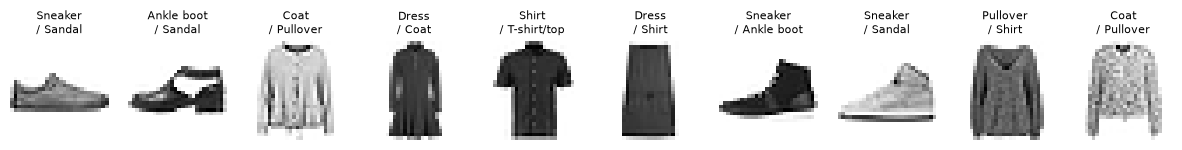

Exercise validated!


In [14]:
### START CODE HERE ###
wrong = torch.nonzero(pred != y_test).flatten()     # indices des images mal classées, forme (n,)
### END CODE HERE ###

assert wrong.ndim == 1, "wrong must be a 1-D tensor of indices"
assert len(wrong) == int((1 - test_acc) * 10000 + 0.5), "one index per misclassified test image"
show_images(X_test_raw[wrong], [f"{CLASSES[y_test[i]]}\n/ {CLASSES[pred[i]]}" for i in wrong[:10]])
print("Exercise validated!")

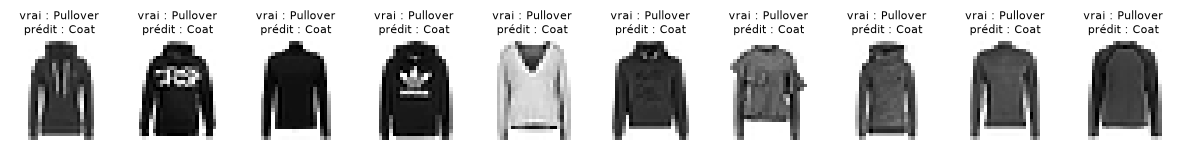

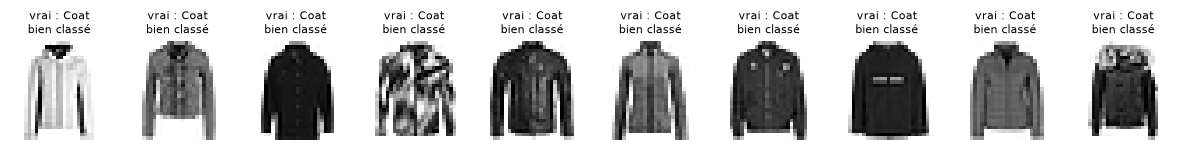

In [15]:
# Zoom sur l'erreur la plus fréquente : 10 images de cette confusion...
idx_err = torch.nonzero((y_test == int(true_cls)) & (pred == int(pred_cls))).flatten()
show_images(X_test_raw[idx_err], [f"vrai : {CLASSES[true_cls]}\nprédit : {CLASSES[pred_cls]}"] * 10)
# ... et, pour comparer, 10 images bien classées de la classe prédite
idx_ok = torch.nonzero((y_test == int(pred_cls)) & (pred == int(pred_cls))).flatten()
show_images(X_test_raw[idx_ok], [f"vrai : {CLASSES[pred_cls]}\nbien classé"] * 10)

💡 **Aurais-tu fait mieux ?** (question 4 de la slide 7)

Honnêtement, pas toujours. À 28×28 pixels en niveaux de gris, une chemise sans boutons visibles ressemble à un T-shirt, et un pull à un manteau fermé. Certaines étiquettes sont même discutables. Le dépôt officiel de FashionMNIST rapporte une précision humaine d'environ 83.5 % (des personnes sans expertise de la mode, sur 1000 images) : notre petit réseau (85.8 %) fait déjà au moins aussi bien. En revanche, un humain ne confondrait jamais un sac avec une basket : quand le réseau fait ce genre d'erreur, c'est qu'il regarde des formes globales de pixels sans comprendre l'objet.

Ce qui manque au réseau : la **structure 2D** (perdue par `Flatten`, d'où les convolutions de la session 7) et des **détails fins** (col, boutons, fermeture) que 128 neurones sigmoïdes n'arrivent pas à capter. L'idée naturelle pour faire mieux : **rendre le réseau plus profond**. C'est la suite... et ça ne va pas se passer comme prévu.

In [16]:
print(f"Livrable partie A : précision de test = {test_acc:.1%} | erreur la plus fréquente : "
      f"{CLASSES[true_cls]} prédit {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} fois sur 1000)")

Livrable partie A : précision de test = 85.8% | erreur la plus fréquente : Pullover prédit Coat (194 fois sur 1000)


> ✅ **À retenir (partie A)**
>
> - Le pipeline complet : `.data / 255`, séparation entraînement / validation / test, standardisation avec les statistiques **de l'entraînement**, `DataLoader`, `Flatten` + `nn.Linear`, `CrossEntropyLoss` sur des **logits**, SGD, `fit`.
> - Le test se mesure **une seule fois**, à la fin.
> - La matrice de confusion dit **quelles** classes sont confondues : ici les hauts (chemise, T-shirt, pull, manteau).

---
# 🗳️ Prédiction (slide 8) : et si on rendait le réseau plus profond ?

> **Énoncé** : mêmes données, même SGD, même pas d'apprentissage, mais **6 couches cachées** de 128 neurones sigmoïdes au lieu d'une.
>
> 1. Après 5 époques, le réseau à 6 couches atteint : (a) plus que le réseau à 1 couche, (b) à peu près pareil, (c) moins, (d) environ 10 %.
> 2. Justifier en une phrase.

**Réponse : (d), environ 10 %**, c'est-à-dire le niveau du hasard (une chance sur 10 classes).

**Justification en une phrase** : la backpropagation multiplie le gradient par $w\,\sigma'(z)$ à chaque couche qu'elle remonte, et comme $\sigma' \le 1/4$, le gradient qui arrive aux premières couches est des milliers de fois plus petit que celui de la sortie ; elles ne bougent pas, leurs sorties restent aléatoires, et les dernières couches n'ont rien d'utile à apprendre.

**Le symptôme** (slide 9) : la loss reste bloquée à $\ln 10 \approx 2.30$, exactement la loss d'un réseau qui répond $1/10$ pour chaque classe. Ce n'est **pas** un bug dans le code, et ce n'est pas un manque de paramètres : il y en a même plus (184 330 contre 101 770).

Pourquoi l'intuition « plus de couches = mieux » est fausse ici : un réseau plus profond **peut** représenter des fonctions plus riches, mais encore faut-il que l'entraînement trouve les bons poids. Ici c'est l'**optimisation** qui échoue, pas la capacité du modèle. On le vérifie à l'exercice TP 12, après avoir compris pourquoi avec les deux exercices du cours qui suivent.

---
# Exercice du cours 1 : à quelle vitesse le gradient disparaît-il ? (slide 13)

> **Énoncé** : une chaîne de neurones sigmoïdes, un par couche, tous les poids $w^{[l]} = 1$.
>
> 1. Donner une borne supérieure de $|\partial a^{[5]} / \partial a^{[0]}|$ pour 5 couches, puis pour 10 couches.
> 2. En pratique les $z^{[l]}$ ne sont pas tous nuls. Avec $z = (0.5, -1, 2, 1, -0.5)$ et $\sigma(z) = (0.622, 0.269, 0.881, 0.731, 0.378)$, calculer les cinq $\sigma'(z^{[l]})$ et leur produit.
> 3. La dernière couche reçoit un gradient de l'ordre de 1 et $\eta = 0.1$. Quel est l'ordre de grandeur de la mise à jour du poids de la première couche, avec 5 couches ?
> 4. Pourrait-on corriger le problème avec de grands poids, par exemple $w = 4$, pour que $w\,\sigma'(0) = 1$ ?

```
a[0] --w[1]--> z[1] --σ--> a[1] --w[2]--> z[2] --σ--> a[2]  ...  --w[5]--> z[5] --σ--> a[5]
```

## 📖 Le cours : la backpropagation multiplie une dérivée par couche (slide 11)

Chaque couche calcule $z^{[l]} = w^{[l]} a^{[l-1]} + b^{[l]}$ puis $a^{[l]} = \sigma(z^{[l]})$. Pour savoir de combien $a^{[L]}$ bouge quand $a^{[0]}$ bouge, la règle de la chaîne (session 3) multiplie les pentes de chaque maillon :

$$\frac{\partial a^{[L]}}{\partial a^{[0]}} = \prod_{l=1}^{L} \frac{\partial a^{[l]}}{\partial a^{[l-1]}} = \prod_{l=1}^{L} \underbrace{\frac{\partial a^{[l]}}{\partial z^{[l]}}}_{\sigma'(z^{[l]})}\ \underbrace{\frac{\partial z^{[l]}}{\partial a^{[l-1]}}}_{w^{[l]}} = \prod_{l=1}^{L} w^{[l]}\,\sigma'(z^{[l]})$$

Avec des matrices, c'est la même structure : $dZ^{[l]} = W^{[l+1]\top} dZ^{[l+1]} \odot \sigma'(Z^{[l]})$. Chaque couche qu'on remonte multiplie le gradient par les poids **et** par $\sigma'$.

**Conséquence** : le gradient qui arrive à la première couche est un **produit de $L$ facteurs**. Si chaque facteur est plus petit que 1, il diminue **exponentiellement** avec la profondeur : c'est le **vanishing gradient** (gradient qui disparaît). Si chaque facteur est plus grand que 1, il explose (**exploding gradient**).

## 📖 La dérivée de la sigmoïde vaut au plus 1/4 (slide 12)

On sait (session 2) que $\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$. On pose $s = \sigma(z) \in (0, 1)$ et on cherche le maximum de $g(s) = s(1 - s)$ en annulant sa dérivée :

$$g'(s) = 1 - 2s = 0 \iff s = \tfrac{1}{2} \qquad\Longrightarrow\qquad \max_z \sigma'(z) = \tfrac{1}{2}\left(1 - \tfrac{1}{2}\right) = \tfrac{1}{4}, \ \text{atteint en } z = 0$$

($s = 1/2$ correspond à $z = 0$, puisque $\sigma(0) = 1/2$.) Donc **même dans le meilleur cas**, chaque couche sigmoïde divise le gradient par 4. Et dès que $|z|$ est grand, le neurone **sature** : $\sigma'(5) \approx 0.0066$.

## ✍️ Question 1 : la borne supérieure

Avec $w^{[l]} = 1$, chaque facteur vaut $1 \times \sigma'(z^{[l]}) \le 1/4$, donc :

$$\left|\frac{\partial a^{[5]}}{\partial a^{[0]}}\right| \le \left(\frac{1}{4}\right)^5 = \frac{1}{1024} \approx 9.8 \times 10^{-4} \approx 10^{-3}$$

$$\left|\frac{\partial a^{[10]}}{\partial a^{[0]}}\right| \le \left(\frac{1}{4}\right)^{10} = \frac{1}{1\,048\,576} \approx 9.5 \times 10^{-7} \approx 10^{-6}$$

Chaque tranche de 5 couches divise le gradient par environ 1000. Et c'est une borne **optimiste** : elle suppose que tous les $z$ valent exactement 0.

## ✍️ Question 2 : avec de vrais $z$

On utilise $\sigma'(z) = s(1 - s)$ avec les valeurs $s = \sigma(z)$ données :

| couche $l$ | $z^{[l]}$ | $s = \sigma(z^{[l]})$ | $1 - s$ | $\sigma'(z^{[l]}) = s(1 - s)$ |
|---|---|---|---|---|
| 1 | 0.5 | 0.622 | 0.378 | **0.235** |
| 2 | -1 | 0.269 | 0.731 | **0.197** |
| 3 | 2 | 0.881 | 0.119 | **0.105** |
| 4 | 1 | 0.731 | 0.269 | **0.197** |
| 5 | -0.5 | 0.378 | 0.622 | **0.235** |

Remarque : $\sigma'$ est **symétrique** ($\sigma'(-z) = \sigma'(z)$), d'où les paires égales (couches 1 et 5, couches 2 et 4).

Le produit, étape par étape :

$$0.235 \times 0.197 \approx 0.0462 \ \xrightarrow{\ \times\, 0.105\ }\ 0.00485 \ \xrightarrow{\ \times\, 0.197\ }\ 0.000953 \ \xrightarrow{\ \times\, 0.235\ }\ 0.000224$$

$$\prod_{l=1}^{5} \sigma'(z^{[l]}) \approx \mathbf{2.2 \times 10^{-4}}$$

C'est environ **4.4 fois plus petit** que la borne $(1/4)^5 \approx 9.8 \times 10^{-4}$ : dès que les $z$ s'éloignent de 0, c'est pire. La couche 3 ($z = 2$) divise à elle seule par presque 10.

## ✍️ Question 3 : l'ordre de grandeur de la mise à jour

Le poids $w^{[1]}$ agit sur $z^{[1]}$, qui agit sur toute la suite de la chaîne :

$$\frac{\partial \mathcal{L}}{\partial w^{[1]}} = \underbrace{\frac{\partial \mathcal{L}}{\partial a^{[5]}}}_{\sim\, 1} \times \underbrace{\sigma'(z^{[1]}) \prod_{l=2}^{5} w^{[l]}\,\sigma'(z^{[l]})}_{=\ \prod \sigma'\ \approx\ 2.2 \times 10^{-4}} \times \underbrace{a^{[0]}}_{\text{l'entrée, } \sim\, 1}$$

Donc $\partial \mathcal{L} / \partial w^{[1]} \sim 2 \times 10^{-4}$, et la mise à jour vaut :

$$|\Delta w^{[1]}| = \eta \left|\frac{\partial \mathcal{L}}{\partial w^{[1]}}\right| \approx 0.1 \times 2.2 \times 10^{-4} \approx \mathbf{2 \times 10^{-5}}, \ \text{de l'ordre de } 10^{-5}$$

(au mieux $0.1 \times 10^{-3} = 10^{-4}$ avec la borne de la question 1.)

**Ce que ça veut dire concrètement** : pour que $w^{[1]}$ change de 0.1 (un changement qui compte), il faudrait environ $0.1 / (2 \times 10^{-5}) = 5\,000$ pas de gradient, tous dans le même sens. Dans le TP, 5 époques font $5 \times 391 \approx 2\,000$ pas. La première couche **ne bouge pratiquement pas**, pendant que la dernière (gradient $\sim 1$, mise à jour $\sim 0.1$) change à chaque pas.

## ✍️ Question 4 : et avec de grands poids, $w = 4$ ?

**Non, ça ne marche pas.** Avec $w = 4$, le facteur de chaque couche est $w\,\sigma'(z) = 4\,\sigma'(z)$ :

- il vaut 1 **seulement si $z = 0$ exactement** ; partout ailleurs il est **plus petit que 1** (car $\sigma'(z) < 1/4$ dès que $z \ne 0$). Le produit continue donc de diminuer avec la profondeur ;
- pire, de grands poids **éloignent $z$ de 0** : $z = 4a + b$ avec $a \in (0, 1)$. Par exemple avec $a = 0.5$ et $b = 0$, $z = 2$, $\sigma'(2) = 0.105$ et le facteur vaut $4 \times 0.105 = 0.42$. Plus on augmente $w$ pour compenser, plus $|z|$ grandit et plus le neurone **sature** ($\sigma' \to 0$) ;
- dans un vrai réseau (des centaines d'entrées par neurone), de grands poids donnent des $z$ énormes : presque tous les neurones saturent (on le calcule à l'exercice du cours 3, question 2).

**Le vrai coupable, c'est la sigmoïde**, pas les poids : sa dérivée est petite (au plus 1/4) et s'écrase vers 0 dès qu'on s'éloigne de 0. On ne peut pas avoir à la fois $w\,\sigma'(z) \approx 1$ et des $z$ variés. La solution : une activation dont la dérivée vaut **exactement 1** sur toute une demi-droite, **quel que soit** $z > 0$ : la **ReLU**.

## 💻 Vérification en Python

Pour la vérification avec autograd, on construit une vraie chaîne de 5 neurones ($w = 1$) en choisissant les biais pour retrouver exactement les $z$ de l'énoncé : on part de $a^{[0]} = 0$ et on prend $b^{[l]} = z^{[l]} - a^{[l-1]}$.

In [17]:
s_enonce = np.array([0.622, 0.269, 0.881, 0.731, 0.378])   # sigma(z[l]) donnés par l'énoncé
d_sig = s_enonce * (1 - s_enonce)                          # sigma'(z[l]) = s (1 - s)
prod = np.prod(d_sig)
print(f"Question 1 : borne pour 5 couches  (1/4)^5  = {0.25 ** 5:.2e}")
print(f"             borne pour 10 couches (1/4)^10 = {0.25 ** 10:.2e}")
print("Question 2 : sigma'(z[l]) =", np.round(d_sig, 3))
print(f"             produit = {prod:.2e}, soit {0.25 ** 5 / prod:.1f} fois plus petit que la borne")
print(f"Question 3 : mise à jour du premier poids ~ 0.1 x {prod:.1e} = {0.1 * prod:.1e}")

# Vérification avec autograd : une vraie chaîne de 5 neurones sigmoïdes, w = 1
z_enonce = torch.tensor([0.5, -1.0, 2.0, 1.0, -0.5])
a0 = torch.tensor(0.0, requires_grad=True)
a = a0
for l in range(5):
    b = z_enonce[l] - a.detach()       # biais choisi pour que z[l] ait la valeur de l'énoncé
    a = torch.sigmoid(1.0 * a + b)     # w[l] = 1
a.backward()
print(f"\nautograd : d a[5] / d a[0] = {a0.grad.item():.2e}  (le même produit)")

# Question 4 : le facteur 4 sigma'(z) n'atteint 1 qu'en z = 0
print("\nQuestion 4 : facteur w sigma'(z) avec w = 4")
for zv in [0, 0.5, 1, 2, 3, 5]:
    sv = 1 / (1 + math.exp(-zv))
    print(f"  z = {zv}: 4 sigma'(z) = {4 * sv * (1 - sv):.3f}")

Question 1 : borne pour 5 couches  (1/4)^5  = 9.77e-04
             borne pour 10 couches (1/4)^10 = 9.54e-07
Question 2 : sigma'(z[l]) = [0.235 0.197 0.105 0.197 0.235]
             produit = 2.24e-04, soit 4.4 fois plus petit que la borne
Question 3 : mise à jour du premier poids ~ 0.1 x 2.2e-04 = 2.2e-05

autograd : d a[5] / d a[0] = 2.24e-04  (le même produit)

Question 4 : facteur w sigma'(z) avec w = 4
  z = 0: 4 sigma'(z) = 1.000
  z = 0.5: 4 sigma'(z) = 0.940
  z = 1: 4 sigma'(z) = 0.786
  z = 2: 4 sigma'(z) = 0.420
  z = 3: 4 sigma'(z) = 0.181
  z = 5: 4 sigma'(z) = 0.027


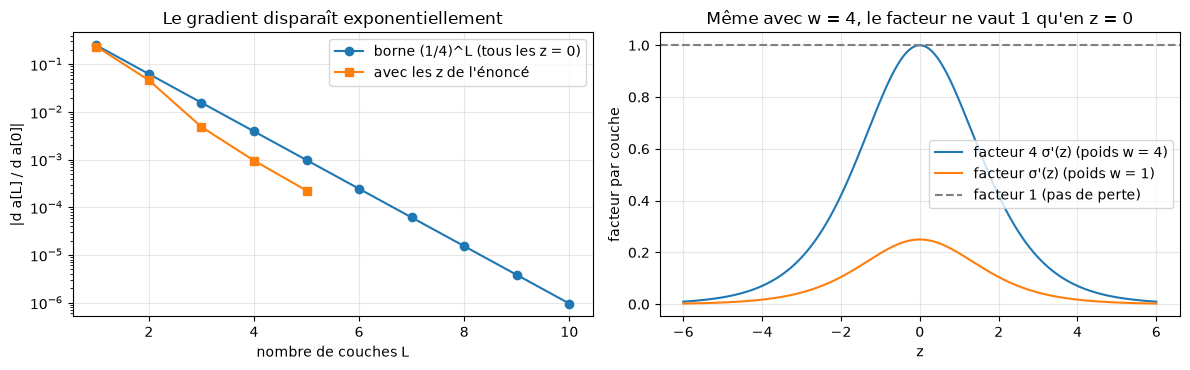

In [18]:
zz = np.linspace(-6, 6, 601)
sg = 1 / (1 + np.exp(-zz))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

L = np.arange(1, 11)
axes[0].semilogy(L, 0.25 ** L, "o-", label="borne (1/4)^L (tous les z = 0)")
axes[0].semilogy(np.arange(1, 6), np.cumprod(d_sig), "s-", label="avec les z de l'énoncé")
axes[0].set(xlabel="nombre de couches L", ylabel="|d a[L] / d a[0]|", title="Le gradient disparaît exponentiellement")
axes[0].legend()

axes[1].plot(zz, 4 * sg * (1 - sg), label="facteur 4 σ'(z) (poids w = 4)")
axes[1].plot(zz, sg * (1 - sg), label="facteur σ'(z) (poids w = 1)")
axes[1].axhline(1, color="gray", ls="--", label="facteur 1 (pas de perte)")
axes[1].set(xlabel="z", ylabel="facteur par couche", title="Même avec w = 4, le facteur ne vaut 1 qu'en z = 0")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> ✅ **À retenir (exercice du cours 1)**
>
> - La backpropagation multiplie **un facteur $w\,\sigma'(z)$ par couche** : le gradient de la première couche est un produit de $L$ facteurs.
> - $\sigma' \le 1/4$ : au mieux $(1/4)^L$, soit $10^{-3}$ pour 5 couches et $10^{-6}$ pour 10. En pratique, c'est encore pire.
> - Les premières couches reçoivent des mises à jour minuscules : elles n'apprennent pas.
> - De grands poids ne règlent rien : ils font saturer la sigmoïde. Il faut changer d'**activation**.

---
# Exercice du cours 2 : une chaîne ReLU, forward et backward (slide 15)

> **Énoncé**
>
> $$z_1 = w_1 x + b_1, \quad a_1 = \text{ReLU}(z_1), \qquad z_2 = w_2 a_1 + b_2, \quad a_2 = \text{ReLU}(z_2), \qquad \hat{y} = w_3 a_2, \quad \mathcal{L} = \tfrac{1}{2}(\hat{y} - y)^2$$
>
> avec $x = 2$, $y = 3$, $w_1 = 0.5$, $b_1 = 1$, $w_2 = -1$, $b_2 = 3$, $w_3 = 2$.
>
> 1. Forward : calculer $z_1, a_1, z_2, a_2, \hat{y}$ et $\mathcal{L}$.
> 2. Backward : calculer $\partial \mathcal{L}/\partial w_3$, $\partial \mathcal{L}/\partial w_2$ et $\partial \mathcal{L}/\partial w_1$.
> 3. Même question avec $b_2 = 0$. Que deviennent les gradients de $w_1$ et $w_2$ ?
>
> *Indice : partir de $\partial \mathcal{L}/\partial \hat{y} = \hat{y} - y$ et multiplier par une dérivée locale à chaque étape.*

```
x --w1,b1--> z1 --ReLU--> a1 --w2,b2--> z2 --ReLU--> a2 --w3--> y_hat --> L = (y_hat - y)^2 / 2
```

## 📖 Le cours : la ReLU (slide 14)

$$\text{ReLU}(z) = \max(0, z), \qquad \text{ReLU}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z < 0 \end{cases}$$

- sur un chemin **actif** ($z > 0$), la dérivée vaut **exactement 1** : le produit des dérivées ne rétrécit pas avec la profondeur ;
- pas de saturation pour $z > 0$, contrairement à la sigmoïde ;
- très peu coûteuse : une comparaison, pas d'exponentielle ;
- toujours **non linéaire** (le coude en 0), donc empiler des couches reste utile (session 3) ;
- popularisée par Nair et Hinton (2010), Glorot et al. (2011), puis AlexNet (2012) : c'est le choix par défaut pour les couches cachées depuis.

(En $z = 0$ exactement, la dérivée n'est pas définie ; PyTorch prend 0 par convention. Ça n'arrive presque jamais en pratique.)

📖 **La méthode du backward** : on part de la fin et on remonte, en multipliant à chaque étape par la **dérivée locale** de l'opération traversée.

| Opération | Dérivées locales |
|---|---|
| $\mathcal{L} = \frac{1}{2}(\hat{y} - y)^2$ | $\partial \mathcal{L}/\partial \hat{y} = \hat{y} - y$ |
| $\hat{y} = w_3 a_2$ | $\partial \hat{y}/\partial w_3 = a_2$, $\quad \partial \hat{y}/\partial a_2 = w_3$ |
| $a_2 = \text{ReLU}(z_2)$ | $\partial a_2/\partial z_2 = \text{ReLU}'(z_2)$ (1 ou 0) |
| $z_2 = w_2 a_1 + b_2$ | $\partial z_2/\partial w_2 = a_1$, $\quad \partial z_2/\partial a_1 = w_2$, $\quad \partial z_2/\partial b_2 = 1$ |
| $a_1 = \text{ReLU}(z_1)$ | $\partial a_1/\partial z_1 = \text{ReLU}'(z_1)$ |
| $z_1 = w_1 x + b_1$ | $\partial z_1/\partial w_1 = x$, $\quad \partial z_1/\partial b_1 = 1$ |

C'est le motif de la session 3 : **gradient d'un poids = (gradient qui arrive) × (l'entrée de ce poids)**.

## ✍️ Question 1 : le forward

| Étape | Formule | Calcul | Valeur |
|---|---|---|---|
| $z_1$ | $w_1 x + b_1$ | $0.5 \times 2 + 1$ | **2** |
| $a_1$ | $\text{ReLU}(z_1)$ | $\max(0, 2)$ | **2** |
| $z_2$ | $w_2 a_1 + b_2$ | $(-1) \times 2 + 3$ | **1** |
| $a_2$ | $\text{ReLU}(z_2)$ | $\max(0, 1)$ | **1** |
| $\hat{y}$ | $w_3 a_2$ | $2 \times 1$ | **2** |
| $\mathcal{L}$ | $\frac{1}{2}(\hat{y} - y)^2$ | $\frac{1}{2}(2 - 3)^2$ | **0.5** |

Les deux ReLU sont **actives** ($z_1 = 2 > 0$ et $z_2 = 1 > 0$) : elles laissent passer leur entrée telle quelle.

## ✍️ Question 2 : le backward

1. **Départ** : $\dfrac{\partial \mathcal{L}}{\partial \hat{y}} = \hat{y} - y = 2 - 3 = -1$ (le réseau prédit trop bas).
2. **Poids $w_3$** (son entrée est $a_2$) : $\dfrac{\partial \mathcal{L}}{\partial w_3} = \dfrac{\partial \mathcal{L}}{\partial \hat{y}} \times a_2 = (-1) \times 1 = \mathbf{-1}$
3. **On traverse $w_3$** : $\dfrac{\partial \mathcal{L}}{\partial a_2} = \dfrac{\partial \mathcal{L}}{\partial \hat{y}} \times w_3 = (-1) \times 2 = -2$
4. **On traverse la ReLU 2** ($z_2 = 1 > 0$, dérivée 1) : $\dfrac{\partial \mathcal{L}}{\partial z_2} = (-2) \times 1 = -2$
5. **Poids $w_2$** (son entrée est $a_1$) : $\dfrac{\partial \mathcal{L}}{\partial w_2} = \dfrac{\partial \mathcal{L}}{\partial z_2} \times a_1 = (-2) \times 2 = \mathbf{-4}$
6. **On traverse $w_2$** : $\dfrac{\partial \mathcal{L}}{\partial a_1} = \dfrac{\partial \mathcal{L}}{\partial z_2} \times w_2 = (-2) \times (-1) = 2$
7. **On traverse la ReLU 1** ($z_1 = 2 > 0$, dérivée 1) : $\dfrac{\partial \mathcal{L}}{\partial z_1} = 2 \times 1 = 2$
8. **Poids $w_1$** (son entrée est $x$) : $\dfrac{\partial \mathcal{L}}{\partial w_1} = \dfrac{\partial \mathcal{L}}{\partial z_1} \times x = 2 \times 2 = \mathbf{4}$

Toute la chaîne d'un coup pour $w_1$ :

$$\frac{\partial \mathcal{L}}{\partial w_1} = \underbrace{(\hat{y} - y)}_{-1} \cdot \underbrace{w_3}_{2} \cdot \underbrace{\text{ReLU}'(z_2)}_{1} \cdot \underbrace{w_2}_{-1} \cdot \underbrace{\text{ReLU}'(z_1)}_{1} \cdot \underbrace{x}_{2} = 4$$

**Lecture** : les deux ReLU ont multiplié le gradient par **1**. Rien n'est perdu en route : le gradient de $w_1$ (la première couche) est aussi grand que ceux des couches suivantes. Avec des sigmoïdes, chacun de ces deux facteurs aurait valu au plus 0.25. (Bonus : $\partial \mathcal{L}/\partial b_2 = -2$ et $\partial \mathcal{L}/\partial b_1 = 2$, car l'entrée d'un biais vaut toujours 1.)

**Les signes** : $w_3$ et $w_2$ ont un gradient négatif, donc la descente de gradient va les **augmenter**, ce qui fait monter $\hat{y}$ vers 3. $w_1$ a un gradient positif : augmenter $w_1$ augmente $a_1$, qui passe par $w_2 = -1$ et fait **baisser** $\hat{y}$. La descente de gradient va donc **baisser** $w_1$.

## ✍️ Question 3 : avec $b_2 = 0$

**Forward** : rien ne change avant $b_2$ ($z_1 = 2$, $a_1 = 2$), puis :

$$z_2 = (-1) \times 2 + 0 = -2 < 0 \ \Rightarrow\ a_2 = \text{ReLU}(-2) = 0, \qquad \hat{y} = 2 \times 0 = 0, \qquad \mathcal{L} = \tfrac{1}{2}(0 - 3)^2 = 4.5$$

**Backward** : $\partial \mathcal{L}/\partial \hat{y} = 0 - 3 = -3$, puis :

- $\dfrac{\partial \mathcal{L}}{\partial w_3} = (-3) \times a_2 = (-3) \times 0 = \mathbf{0}$ (l'entrée de $w_3$ est nulle) ;
- $\dfrac{\partial \mathcal{L}}{\partial a_2} = (-3) \times 2 = -6$, mais on traverse la ReLU 2 avec $z_2 = -2 < 0$ : **dérivée 0**, donc $\dfrac{\partial \mathcal{L}}{\partial z_2} = (-6) \times 0 = 0$ ;
- $\dfrac{\partial \mathcal{L}}{\partial w_2} = 0 \times a_1 = \mathbf{0}$ ;
- $\dfrac{\partial \mathcal{L}}{\partial w_1} = 0 \times w_2 \times \text{ReLU}'(z_1) \times x = \mathbf{0}$.

**Les gradients de $w_1$ et $w_2$ sont exactement nuls** (ceux de $w_3$, $b_1$ et $b_2$ aussi), alors que la loss est grande (4.5) ! La ReLU 2 est **éteinte** : elle renvoie 0 et sa dérivée vaut 0, donc elle **coupe** tout le gradient qui voudrait remonter vers les couches d'avant. La descente de gradient ne peut rien corriger pour cet exemple.

➡️ Si $z_2 < 0$ pour **toutes** les entrées du jeu de données, ce neurone ne reçoit plus jamais de gradient et ne peut plus revenir : c'est un **neurone ReLU mort** (dead ReLU, slide 16). C'est le prix de la ReLU, et c'est exactement ce que l'exercice TP 16 provoque exprès.

## 💻 Vérification avec autograd

In [19]:
def chaine_relu(b2_val):
    x, y = torch.tensor(2.0), torch.tensor(3.0)
    w1 = torch.tensor(0.5, requires_grad=True)
    b1 = torch.tensor(1.0, requires_grad=True)
    w2 = torch.tensor(-1.0, requires_grad=True)
    b2 = torch.tensor(b2_val, requires_grad=True)
    w3 = torch.tensor(2.0, requires_grad=True)
    z1 = w1 * x + b1
    a1 = torch.relu(z1)
    z2 = w2 * a1 + b2
    a2 = torch.relu(z2)
    y_hat = w3 * a2
    L = 0.5 * (y_hat - y) ** 2
    L.backward()
    g = lambda t: t.grad.item() + 0.0      # le "+ 0.0" transforme un éventuel -0.0 en 0.0
    print(f"b2 = {b2_val}")
    print(f"  forward  : z1 = {z1.item()}, a1 = {a1.item()}, z2 = {z2.item()}, a2 = {a2.item()}, "
          f"y_hat = {y_hat.item()}, L = {L.item()}")
    print(f"  backward : dL/dw3 = {g(w3)}, dL/dw2 = {g(w2)}, dL/dw1 = {g(w1)}, dL/db2 = {g(b2)}, dL/db1 = {g(b1)}")


chaine_relu(3.0)     # questions 1 et 2
chaine_relu(0.0)     # question 3 : la ReLU 2 est éteinte, tous les gradients sont nuls

b2 = 3.0
  forward  : z1 = 2.0, a1 = 2.0, z2 = 1.0, a2 = 1.0, y_hat = 2.0, L = 0.5
  backward : dL/dw3 = -1.0, dL/dw2 = -4.0, dL/dw1 = 4.0, dL/db2 = -2.0, dL/db1 = 2.0
b2 = 0.0
  forward  : z1 = 2.0, a1 = 2.0, z2 = -2.0, a2 = 0.0, y_hat = 0.0, L = 4.5
  backward : dL/dw3 = 0.0, dL/dw2 = 0.0, dL/dw1 = 0.0, dL/db2 = 0.0, dL/db1 = 0.0


> ✅ **À retenir (exercice du cours 2)**
>
> - Sur un chemin actif, une ReLU multiplie le gradient par **1** : il traverse les couches sans s'affaiblir.
> - Une ReLU éteinte ($z < 0$) multiplie par **0** : elle coupe le gradient de tout ce qui est avant elle.
> - Éteinte pour **toutes** les entrées = neurone **mort**, qui ne reviendra jamais.

---
# Partie B : un réseau sigmoïde profond (TP, exercices 9 à 12)

On passe à la pratique : on construit le réseau à 6 couches, on **mesure** le gradient de chaque couche, et on vérifie la prédiction de la slide 8.

## Exercice TP 9 : un réseau de profondeur quelconque

> **Énoncé** : écrire `make_mlp(depth, activation, width=128)` qui renvoie un `nn.Sequential` : `nn.Flatten()`, puis `depth` blocs cachés `nn.Linear(n_in, width)` suivis de `activation()`, puis `nn.Linear(width, 10)`. La première couche cachée a `n_in = 784`, les suivantes `n_in = width`.

📖 **Ce qu'il faut savoir**

- `activation` est une **classe** (`nn.Sigmoid`, `nn.ReLU`...), pas une couche : `activation()` **crée** une nouvelle couche de ce type. C'est ce qui permet d'écrire **une seule** fonction pour toutes les activations (exercice TP 15).
- On accumule les couches dans une liste Python `layers`, puis `nn.Sequential(*layers)` : l'étoile **dépaquette** la liste, c'est comme écrire `nn.Sequential(layers[0], layers[1], ...)`.
- `n_in` vaut 784 pour la première couche cachée, puis `width` : la sortie d'une couche est l'entrée de la suivante. On met à jour `n_in = width` après chaque bloc.
- **Pas d'activation après la dernière couche** : elle produit les logits pour `CrossEntropyLoss`.

✍️ Pour `make_mlp(6, nn.Sigmoid)` : 7 `nn.Linear` (6 cachées + 1 de sortie), 6 `nn.Sigmoid`, et

$$\underbrace{784 \times 128 + 128}_{100\,480} + 5 \times \underbrace{(128 \times 128 + 128)}_{16\,512} + \underbrace{128 \times 10 + 10}_{1\,290} = 184\,330 \text{ paramètres.}$$

In [20]:
def make_mlp(depth, activation, width=128):
    ### START CODE HERE ###
    layers = [nn.Flatten()]                        # (B, 28, 28) -> (B, 784)
    n_in = 784
    for _ in range(depth):
        layers.append(nn.Linear(n_in, width))      # une couche cachée
        layers.append(activation())                # activation() crée une NOUVELLE couche d'activation
        n_in = width                               # la couche suivante reçoit width valeurs
    layers.append(nn.Linear(n_in, 10))             # sortie : 10 logits, sans activation
    ### END CODE HERE ###
    return nn.Sequential(*layers)


deep = make_mlp(6, nn.Sigmoid)
linears = [m for m in deep if isinstance(m, nn.Linear)]
print(deep)
assert len(linears) == 7, f"6 hidden layers + 1 output layer = 7 nn.Linear, got {len(linears)}"
assert sum(isinstance(m, nn.Sigmoid) for m in deep) == 6, "one activation after each hidden layer, none after the output"
assert linears[0].in_features == 784 and linears[-1].out_features == 10, "784 inputs, 10 logits"
assert deep(xb).shape == (BATCH_SIZE, 10), "the output must be (B, 10)"
print("Exercise validated!")
print("nombre de paramètres :", sum(p.numel() for p in deep.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): Sigmoid()
  (5): Linear(in_features=128, out_features=128, bias=True)
  (6): Sigmoid()
  (7): Linear(in_features=128, out_features=128, bias=True)
  (8): Sigmoid()
  (9): Linear(in_features=128, out_features=128, bias=True)
  (10): Sigmoid()
  (11): Linear(in_features=128, out_features=128, bias=True)
  (12): Sigmoid()
  (13): Linear(in_features=128, out_features=10, bias=True)
)
Exercise validated!
nombre de paramètres : 184330


## Exercice TP 10 : le maximum de $\sigma'$, avec autograd

> **Énoncé** : `z` est une grille de 1201 points de -6 à 6 qui demande des gradients. Calculer `s = torch.sigmoid(z)`, appeler `s.sum().backward()`, stocker `z.grad` dans `dsig`, puis `max_dsig` (le maximum, un float Python) et `z_at_max` (l'endroit où il est atteint).

📖 **L'astuce de la somme.** `backward()` calcule le gradient d'**un seul nombre** (un scalaire). Ici on veut 1201 dérivées. On dérive donc la somme $S = \sum_j \sigma(z_j)$ : comme chaque terme $\sigma(z_j)$ ne dépend que de $z_j$,

$$\frac{\partial S}{\partial z_i} = \frac{\partial}{\partial z_i} \sum_j \sigma(z_j) = \sigma'(z_i)$$

(tous les autres termes de la somme ont une dérivée nulle par rapport à $z_i$). Donc `z.grad` contient exactement les 1201 valeurs $\sigma'(z_i)$.

- `requires_grad=True` sur `z` : PyTorch enregistre les opérations faites sur `z` pour pouvoir dériver ensuite.
- `dsig.argmax()` donne l'**indice** du maximum ; `z[indice]` la valeur de $z$ correspondante.
- La grille a un pas de $12 / 1200 = 0.01$ : l'indice 600 correspond à $z = 0$, l'indice 1100 à $z = -6 + 1100 \times 0.01 = 5$.

Attendu (slide 12) : un maximum de $1/4$ en $z = 0$, et $\sigma'(5) \approx 0.0066$.

In [21]:
z = torch.linspace(-6, 6, 1201, requires_grad=True)
### START CODE HERE ###
s = torch.sigmoid(z)                   # les 1201 valeurs sigma(z_i)
s.sum().backward()                     # d(somme) / dz_i = sigma'(z_i)
dsig = z.grad                          # les 1201 dérivées
max_dsig = dsig.max().item()           # le maximum, en float Python
z_at_max = z[dsig.argmax()].item()     # l'endroit où il est atteint
### END CODE HERE ###

print(f"max of sigmoid' = {max_dsig:.4f} at z = {z_at_max:.2f} | sigmoid'(5) = {dsig[1100].item():.4f}")
assert torch.allclose(dsig, (s * (1 - s)).detach(), atol=1e-6), "dsig should equal sigma(z)(1 - sigma(z))"
assert abs(max_dsig - 0.25) < 1e-6 and abs(z_at_max) < 1e-6, "the maximum is 1/4, at z = 0"
print("Exercise validated!")

max of sigmoid' = 0.2500 at z = 0.00 | sigmoid'(5) = 0.0066
Exercise validated!


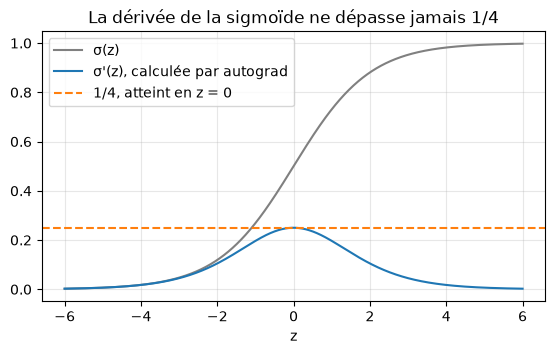

In [22]:
plt.figure(figsize=(6.5, 3.5))
plt.plot(z.detach(), s.detach(), color="gray", label="σ(z)")
plt.plot(z.detach(), dsig, label="σ'(z), calculée par autograd")
plt.axhline(0.25, ls="--", color="C1", label="1/4, atteint en z = 0")
plt.xlabel("z"); plt.legend(); plt.grid(alpha=0.3)
plt.title("La dérivée de la sigmoïde ne dépasse jamais 1/4")
plt.show()

## Exercice TP 11 : la norme du gradient de chaque couche

> **Énoncé** : compléter `layer_grad_norms(model, xb, yb)` : `model.zero_grad()`, forward, loss d'entropie croisée, `backward()`, puis renvoyer la liste `[W.grad.norm().item() pour chaque nn.Linear du modèle, dans l'ordre]`.

📖 **Ce qu'on mesure.** Après un `backward()`, chaque poids `W` a son gradient dans `W.grad` (même forme que `W`). Sa **norme** euclidienne $\|dW\| = \sqrt{\sum_{ij} dW_{ij}^2}$ résume « à quel point cette couche va bouger » au prochain pas, puisque la mise à jour vaut $\eta\, dW$.

- `model.zero_grad()` d'abord : PyTorch **additionne** les gradients à chaque `backward()`. Sans remise à zéro, on mesurerait la somme avec un calcul précédent.
- On utilise toujours le même batch fixe de 256 images (`xg`, `yg`) pour pouvoir comparer les modèles entre eux.
- `for m in model` parcourt les couches d'un `nn.Sequential` ; `isinstance(m, nn.Linear)` garde les couches linéaires (on ignore `Flatten` et les activations, qui n'ont pas de poids).

À quoi s'attendre (slide 10) : avec 6 couches sigmoïdes, la première couche reçoit un gradient de l'ordre de $10^{-5}$ et la sortie de l'ordre de 1, soit **des dizaines de milliers de fois moins**.

In [23]:
def layer_grad_norms(model, xb, yb):
    model.train()
    ### START CODE HERE ###
    model.zero_grad()                                    # 1. pas de gradients restants
    loss = nn.CrossEntropyLoss()(model(xb), yb)          # 2. forward + loss
    loss.backward()                                      # 3. backward : remplit W.grad
    norms = [m.weight.grad.norm().item()                 # 4. une norme par nn.Linear, dans l'ordre
             for m in model if isinstance(m, nn.Linear)]
    ### END CODE HERE ###
    return norms


xg, yg = X_train[:256].to(device), y_train[:256].to(device)   # a fixed batch to measure gradients
torch.manual_seed(0)
deep_sig = make_mlp(6, nn.Sigmoid).to(device)
norms_sig = layer_grad_norms(deep_sig, xg, yg)
ratio_sig = norms_sig[0] / norms_sig[-1]
print("gradient norm per layer (first to last):", ["%.1e" % v for v in norms_sig])
print(f"first layer / last layer = {ratio_sig:.1e}")
assert len(norms_sig) == 7, "one norm per nn.Linear (7 for 6 hidden layers)"
assert ratio_sig < 1e-3, "the first layer's gradient should be thousands of times smaller than the last one's"
print("Exercise validated!")

gradient norm per layer (first to last): ['3.6e-05', '3.7e-05', '2.4e-04', '1.9e-03', '1.3e-02', '1.0e-01', '7.7e-01']
first layer / last layer = 4.7e-05
Exercise validated!


Helper du TP (à exécuter) : les normes du gradient en échelle logarithmique.

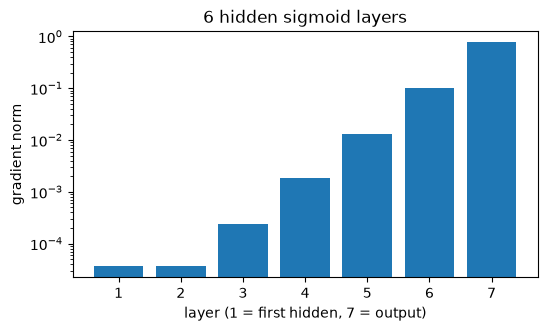

In [24]:
plt.figure(figsize=(6, 3.2))
plt.bar(range(1, 8), norms_sig, color="C0")
plt.yscale("log"); plt.xlabel("layer (1 = first hidden, 7 = output)"); plt.ylabel("gradient norm")
plt.title("6 hidden sigmoid layers"); plt.show()

In [25]:
# De combien le gradient est-il divisé à chaque couche qu'on remonte ?
print("division d'une couche à la précédente (de la sortie vers l'entrée) :",
      [f"{norms_sig[l + 1] / norms_sig[l]:.1f}" for l in reversed(range(6))])

division d'une couche à la précédente (de la sortie vers l'entrée) : ['7.6', '7.9', '6.8', '7.7', '6.6', '1.0']


💡 **Ce qu'on observe.** Le gradient passe de 0.77 pour la couche de sortie à $3.6 \times 10^{-5}$ pour la première couche : environ **20 000 fois moins** (rapport $4.7 \times 10^{-5}$), exactement la figure de la slide 10. En remontant, il est divisé par 6.6 à 7.9 à chaque couche.

**Pourquoi environ 7 par couche, et pas 4 ?** Chaque pas en arrière, $dZ^{[l]} = W^{[l+1]\top} dZ^{[l+1]} \odot \sigma'(Z^{[l]})$, multiplie par **deux** choses :

- $\sigma'(z)$ : à l'initialisation les $z$ sont proches de 0, donc $\sigma' \approx 0.2$ à $0.25$ (division par 4 à 5) ;
- les poids $W^\top$ : avec l'initialisation par défaut de PyTorch, $\text{Var}(w) = 1/(3\,n_\text{in})$ (on le verra en partie D). Multiplier par $W^\top$ multiplie la variance par environ $128 \times \frac{1}{3 \times 128} = \frac{1}{3}$, donc l'écart-type par $1/\sqrt{3} \approx 0.58$.

Ensemble : $0.24 \times 0.58 \approx 0.14$, soit une division par environ 7 à chaque couche. La première couche fait exception (son gradient ressemble à celui de la couche 2) : son entrée, ce sont les 784 pixels standardisés, un vecteur bien plus « gros » que les 128 sorties sigmoïdes qu'ont les autres couches, ce qui compense une division.

## Exercice TP 12 : entraîner le réseau sigmoïde profond

> **Énoncé** : même recette qu'à l'exercice TP 5 (`nn.CrossEntropyLoss`, SGD avec `lr=LR`), sur `deep_sig`, pendant `EPOCHS` époques. Stocker l'historique dans `history_sig`. Prédire avant de lancer : mieux ou moins bien que le réseau à 1 couche ?

C'est la vérification de la prédiction de la slide 8.

In [26]:
torch.manual_seed(0)
### START CODE HERE ###
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(deep_sig.parameters(), lr=LR)     # mêmes réglages que la baseline
history_sig = fit(deep_sig, train_loader, val_loader, loss_fn, optimizer, EPOCHS)
### END CODE HERE ###

assert len(history_sig["val_acc"]) == EPOCHS, "train for EPOCHS epochs"
assert history_sig["val_acc"][-1] < 0.3, "surprise: the deep sigmoid network should stay near chance (0.1)"
print("Exercise validated! Deeper is not better... yet.")

epoch  1 | train loss 2.3180 | val loss 2.3200 | val acc 0.101


epoch  2 | train loss 2.3134 | val loss 2.3210 | val acc 0.097


epoch  3 | train loss 2.3102 | val loss 2.3122 | val acc 0.099


epoch  4 | train loss 2.3087 | val loss 2.3102 | val acc 0.097


epoch  5 | train loss 2.3069 | val loss 2.3071 | val acc 0.103
Exercise validated! Deeper is not better... yet.


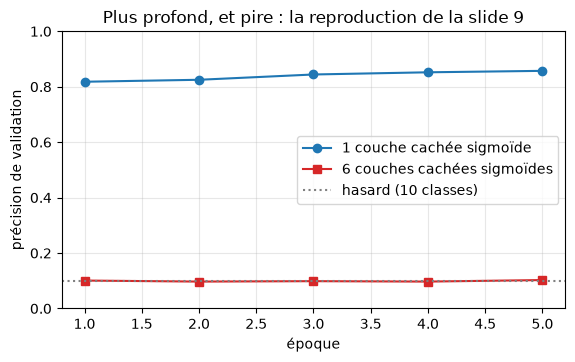

loss de validation finale du réseau profond : 2.3071   (ln 10 = 2.3026)


In [27]:
ep = range(1, EPOCHS + 1)
plt.figure(figsize=(6.5, 3.6))
plt.plot(ep, history_a["val_acc"][:EPOCHS], "o-", label="1 couche cachée sigmoïde")
plt.plot(ep, history_sig["val_acc"], "s-", color="C3", label="6 couches cachées sigmoïdes")
plt.axhline(0.1, color="gray", ls=":", label="hasard (10 classes)")
plt.ylim(0, 1); plt.xlabel("époque"); plt.ylabel("précision de validation"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Plus profond, et pire : la reproduction de la slide 9")
plt.show()
print(f"loss de validation finale du réseau profond : {history_sig['val_loss'][-1]:.4f}   (ln 10 = {math.log(10):.4f})")

💡 **Ce qu'on observe.** La loss reste collée à $\ln 10 \approx 2.30$ et la précision à environ 10 % : le réseau donne à peu près les mêmes probabilités à toutes les images, et prédit donc (presque) toujours la même classe. Il est au niveau du hasard.

**Le mécanisme** :

1. **En arrière** : la première couche reçoit un gradient des dizaines de milliers de fois plus petit que la sortie (exercice TP 11). Elle ne bouge pas, et ses sorties restent des combinaisons **aléatoires** des pixels.
2. **En avant, le même problème** : chaque couche sigmoïde à l'initialisation écrase les différences entre images (les sorties restent autour de 0.5, et les petites variations sont multipliées par $w\,\sigma' \approx 0.14$ à chaque couche). Après 6 couches, la dernière couche cachée renvoie **presque le même vecteur pour toutes les images** : la couche de sortie n'a aucune information pour les distinguer. Le mieux qu'elle puisse faire est de prédire la répartition des classes, qui est uniforme : $p_k = 1/10$, loss $= \ln 10$.

La cellule suivante le vérifie sur le réseau entraîné : on mesure, couche par couche, à quel point les sorties varient **d'une image à l'autre**.

In [28]:
deep_sig.eval()
with torch.no_grad():
    h = xg
    for m in deep_sig:
        h = m(h)
        if isinstance(m, nn.Sigmoid):
            ecart = h.std(dim=0).mean().item()      # variation d'une image à l'autre, moyennée sur les neurones
            print(f"après une couche sigmoïde : moyenne {h.mean().item():.3f} | écart entre images {ecart:.1e}")
    print("classes prédites pour les 256 images :", torch.unique(h.argmax(dim=1)).tolist())

après une couche sigmoïde : moyenne 0.508 | écart entre images 1.1e-01
après une couche sigmoïde : moyenne 0.502 | écart entre images 1.5e-02
après une couche sigmoïde : moyenne 0.515 | écart entre images 2.1e-03
après une couche sigmoïde : moyenne 0.500 | écart entre images 3.1e-04
après une couche sigmoïde : moyenne 0.544 | écart entre images 4.4e-05
après une couche sigmoïde : moyenne 0.256 | écart entre images 4.8e-06
classes prédites pour les 256 images : [1]


💡 L'écart entre images est divisé par environ 7 à chaque couche : 0.11 après la première couche sigmoïde, $5 \times 10^{-6}$ après la sixième. La dernière couche cachée renvoie donc le même vecteur pour toutes les images, et le réseau prédit **la même classe** pour les 256 images (ici la classe 1, Trouser). Le signal disparaît en avant comme le gradient disparaît en arrière, avec le même facteur $w\,\sigma' \approx 0.14$.

> ✅ **À retenir (partie B)**
>
> - Un réseau plus profond n'apprend pas forcément mieux : avec 6 couches sigmoïdes, il reste au **hasard** (loss $\ln 10$).
> - On le **diagnostique** en mesurant la norme du gradient de chaque couche : division par environ 7 par couche en remontant.
> - Ce n'est pas un bug ni un manque de paramètres, c'est le **vanishing gradient** dû à $\sigma' \le 1/4$.

---
# Partie C : ReLU et les autres activations (TP, exercices 13 à 16)

## 📖 Le cours : le tour des fonctions d'activation (slides 14, 17 et 18)

| Activation | Formule | Dérivée maximale | Où l'utiliser | Pourquoi |
|---|---|---|---|---|
| **ReLU** | $\max(0, z)$ | 1 (pour tout $z > 0$) | couches cachées, choix par défaut (MLP, CNN) | dérivée 1, peu coûteuse, ça marche |
| **Leaky ReLU** | $\max(\alpha z, z)$, $\alpha = 0.01$ | 1 | couches cachées, si beaucoup d'unités meurent | le gradient n'est jamais exactement nul |
| **ELU** | $z$ si $z > 0$, $e^z - 1$ sinon | 1 | idem | comme Leaky ReLU, mais lisse |
| **GELU** | $z\,\Phi(z)$, avec $\Phi$ la fonction de répartition de la loi normale | environ 1.13 | couches cachées des transformers (BERT, GPT) | une ReLU lisse, un peu meilleure dans les grands modèles |
| **tanh** | $\dfrac{e^z - e^{-z}}{e^z + e^{-z}} = 2\sigma(2z) - 1$ | 1 (en $z = 0$) | dans les cellules RNN et LSTM (session 8) | bornée dans $(-1, 1)$ et centrée sur 0, mais sature |
| **sigmoïde** | $\dfrac{1}{1 + e^{-z}}$ | 1/4 | sortie à 2 classes ou multi-label ; portes des LSTM | une probabilité dans $(0, 1)$ ; à éviter dans les piles de couches cachées |
| **softmax** | $\dfrac{e^{z_k}}{\sum_j e^{z_j}}$ | | sortie pour $C$ classes exclusives | $C$ probabilités qui somment à 1 (en PyTorch, cachée dans `CrossEntropyLoss`) |

**Règle** : la couche de **sortie** se choisit selon la **tâche** (une probabilité, une distribution sur des classes, ou rien du tout pour une régression). Les couches **cachées** se choisissent pour le **flux du gradient**.

Pourquoi tanh fait mieux que la sigmoïde : $\tanh(z) = 2\sigma(2z) - 1$, donc $\tanh'(z) = 4\,\sigma'(2z)$, dont le maximum vaut $4 \times \frac{1}{4} = 1$. C'est une sigmoïde étirée et centrée sur 0, avec une dérivée **4 fois** plus grande.

La cellule suivante reproduit la figure de la slide 17 (les dérivées sont calculées par autograd, avec l'astuce de la somme de l'exercice TP 10).

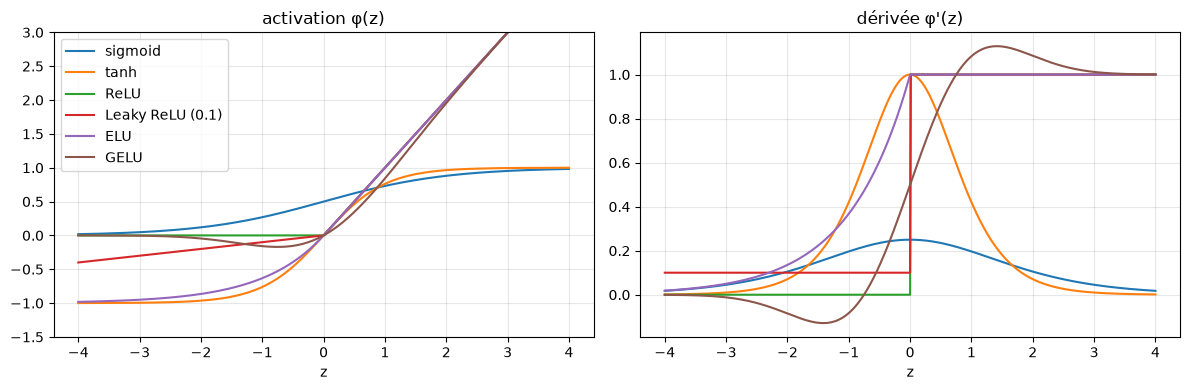

In [29]:
zg = torch.linspace(-4, 4, 801, requires_grad=True)
activations = {
    "sigmoid": torch.sigmoid,
    "tanh": torch.tanh,
    "ReLU": torch.relu,
    "Leaky ReLU (0.1)": lambda t: nn.functional.leaky_relu(t, 0.1),   # pente 0.1 pour qu'on la voie
    "ELU": nn.functional.elu,
    "GELU": nn.functional.gelu,
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, f in activations.items():
    zg.grad = None
    out = f(zg)
    out.sum().backward()                      # dérivée en chaque point
    axes[0].plot(zg.detach(), out.detach(), label=name)
    axes[1].plot(zg.detach(), zg.grad.clone(), label=name)
axes[0].set(title="activation φ(z)", xlabel="z", ylim=(-1.5, 3))
axes[1].set(title="dérivée φ'(z)", xlabel="z")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Exercice TP 13 : la même profondeur avec ReLU

> **Énoncé** : construire `deep_relu = make_mlp(6, nn.ReLU)`, mesurer ses normes de gradient sur `(xg, yg)` (`norms_relu`), et calculer `ratio_relu` (première couche / dernière).

C'est la même fonction `make_mlp` : on change seulement la classe d'activation passée en argument. Attendu (slide 10, barres bleues) : toutes les couches du même ordre de grandeur.

ReLU gradient norm per layer: ['1.7e-02', '6.5e-03', '7.3e-03', '8.1e-03', '9.5e-03', '1.2e-02', '2.6e-02'] | ratio 0.67


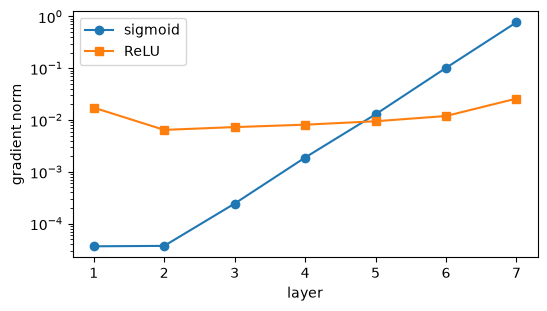

Exercise validated!


In [30]:
torch.manual_seed(0)
### START CODE HERE ###
deep_relu = make_mlp(6, nn.ReLU).to(device)          # même architecture, seule l'activation change
norms_relu = layer_grad_norms(deep_relu, xg, yg)
ratio_relu = norms_relu[0] / norms_relu[-1]          # gradient première couche / dernière
### END CODE HERE ###

print("ReLU gradient norm per layer:", ["%.1e" % v for v in norms_relu], f"| ratio {ratio_relu:.2f}")
assert len(norms_relu) == 7, "one norm per nn.Linear"
assert ratio_relu > 0.1, "with ReLU the first layer should receive a gradient comparable to the last one"
plt.figure(figsize=(6, 3.2))
plt.plot(range(1, 8), norms_sig, "o-", label="sigmoid")
plt.plot(range(1, 8), norms_relu, "s-", label="ReLU")
plt.yscale("log"); plt.xlabel("layer"); plt.ylabel("gradient norm"); plt.legend(); plt.show()
print("Exercise validated!")

💡 **Ce qu'on observe.** Avec ReLU, toutes les normes restent entre $6.5 \times 10^{-3}$ et $2.6 \times 10^{-2}$ : le rapport première/dernière couche vaut 0.67, contre $4.7 \times 10^{-5}$ pour la sigmoïde. C'est la figure de la slide 10 (barres bleues) : toutes les couches recevront un gradient utile.

**Pourquoi ?** En remontant une couche ReLU, chaque neurone actif multiplie le gradient par **1** (au lieu de 0.25 au mieux pour la sigmoïde), et chaque neurone éteint par 0. Il n'y a plus de facteur $\sigma' \le 1/4$ qui écrase le gradient à chaque couche : il garde une taille comparable d'une couche à l'autre, au lieu d'être divisé par 7.

## Exercice TP 14 : entraîner le réseau ReLU profond

> **Énoncé** : même recette, sur `deep_relu`, pendant `EPOCHS` époques. Stocker l'historique dans `history_relu`.

In [31]:
torch.manual_seed(0)
### START CODE HERE ###
optimizer = torch.optim.SGD(deep_relu.parameters(), lr=LR)     # un optimiseur pour CE modèle
history_relu = fit(deep_relu, train_loader, val_loader, loss_fn, optimizer, EPOCHS)
### END CODE HERE ###

assert len(history_relu["val_acc"]) == EPOCHS, "train for EPOCHS epochs"
assert history_relu["val_acc"][-1] > 0.7, f"the deep ReLU network should learn (val acc > 0.7), got {history_relu['val_acc'][-1]:.3f}"
print("Exercise validated!")

epoch  1 | train loss 1.2805 | val loss 0.5905 | val acc 0.778


epoch  2 | train loss 0.5229 | val loss 0.4980 | val acc 0.822


epoch  3 | train loss 0.4208 | val loss 0.4133 | val acc 0.849


epoch  4 | train loss 0.3668 | val loss 0.4175 | val acc 0.844


epoch  5 | train loss 0.3362 | val loss 0.3789 | val acc 0.861
Exercise validated!


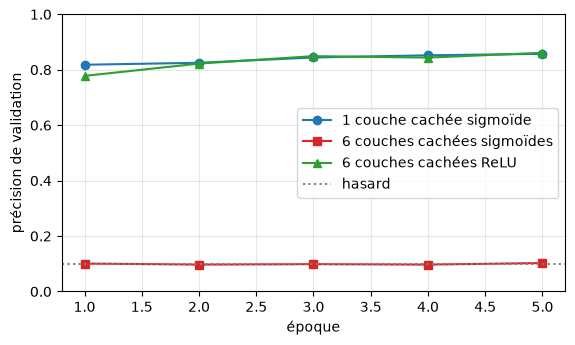

In [32]:
plt.figure(figsize=(6.5, 3.6))
plt.plot(ep, history_a["val_acc"][:EPOCHS], "o-", label="1 couche cachée sigmoïde")
plt.plot(ep, history_sig["val_acc"], "s-", color="C3", label="6 couches cachées sigmoïdes")
plt.plot(ep, history_relu["val_acc"], "^-", color="C2", label="6 couches cachées ReLU")
plt.axhline(0.1, color="gray", ls=":", label="hasard")
plt.ylim(0, 1); plt.xlabel("époque"); plt.ylabel("précision de validation"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

💡 **Ce qu'on observe.** Le réseau ReLU à 6 couches apprend : 77.8 % après une époque, 86.1 % après cinq. Il démarre un peu moins vite que le réseau à une couche (il y a plus de couches à régler), puis le rattrape (86.1 % contre 85.7 % à la 5e époque). Même profondeur que le réseau sigmoïde bloqué à 10 % : **seule l'activation a changé**.

## Exercice TP 15 : quatre activations dans une boucle (livrable)

> **Énoncé** : comparer `nn.Sigmoid`, `nn.Tanh`, `nn.ReLU` et `nn.LeakyReLU` (pente 0.01 pour $z < 0$) sur le même réseau à 6 couches. Pour chaque activation : graine `torch.manual_seed(0)`, construire le réseau, mesurer le rapport de gradient première/dernière couche sur `(xg, yg)`, l'entraîner `EPOCHS` époques (`fit(..., verbose=False)`), et stocker `results[name] = (ratio, précision de validation finale)` avec `name = act.__name__`.

📖 **Ce qu'il faut savoir**

- `act.__name__` est le nom de la classe sous forme de texte : `nn.ReLU.__name__ == "ReLU"`.
- `torch.manual_seed(0)` **avant** chaque construction : les 4 réseaux partent des mêmes tirages aléatoires, la seule différence est l'activation. C'est une comparaison **à armes égales**.
- Un **nouvel optimiseur** pour chaque réseau : un optimiseur est lié aux paramètres d'un modèle précis.
- `nn.LeakyReLU()` a une pente de 0.01 par défaut.

In [33]:
results = {}
for act in [nn.Sigmoid, nn.Tanh, nn.ReLU, nn.LeakyReLU]:
    ### START CODE HERE ###
    torch.manual_seed(0)                                     # même point de départ pour les 4
    net = make_mlp(6, act).to(device)
    norms = layer_grad_norms(net, xg, yg)
    ratio = norms[0] / norms[-1]                             # gradient première couche / dernière
    optimizer = torch.optim.SGD(net.parameters(), lr=LR)     # un nouvel optimiseur pour chaque réseau
    hist = fit(net, train_loader, val_loader, nn.CrossEntropyLoss(), optimizer, EPOCHS, verbose=False)
    results[act.__name__] = (ratio, hist["val_acc"][-1])
    ### END CODE HERE ###

print(f"{'activation':12s} {'grad first/last':>16s} {'val acc':>8s}")
for name, (r, acc) in results.items():
    print(f"{name:12s} {r:16.1e} {acc:8.3f}")
assert set(results) == {"Sigmoid", "Tanh", "ReLU", "LeakyReLU"}, "one entry per activation, named act.__name__"
assert results["Sigmoid"][1] < 0.3, "the deep sigmoid network should fail"
assert min(results[k][1] for k in ["Tanh", "ReLU", "LeakyReLU"]) > 0.7, "tanh, ReLU and LeakyReLU should all learn"
print("Exercise validated!")

activation    grad first/last  val acc
Sigmoid               4.7e-05    0.097
Tanh                  2.0e+00    0.868
ReLU                  6.7e-01    0.864
LeakyReLU             6.7e-01    0.871
Exercise validated!


💡 **Ce qu'on observe (le livrable de l'exercice 15).** Dans notre exécution :

| Activation | Gradient 1re couche / dernière | Précision de validation (5 époques) |
|---|---|---|
| Sigmoid | $4.7 \times 10^{-5}$ | 9.7 % (le hasard) |
| Tanh | 2.0 | 86.8 % |
| ReLU | 0.67 | 86.4 % |
| LeakyReLU | 0.67 | 87.1 % |

Avec tanh, la première couche reçoit même un gradient 2 fois plus grand que la dernière : rien ne disparaît à cette profondeur.

**Comment l'expliquer :**

- **Sigmoid** : la seule qui échoue. Dérivée au plus 1/4 et sorties toujours positives (autour de 0.5, pas centrées) : le gradient de la première couche est des dizaines de milliers de fois plus petit que celui de la sortie.
- **Tanh** : elle sature aussi, mais sa dérivée vaut 1 en $z = 0$ (4 fois celle de la sigmoïde) et elle est centrée sur 0. À cette profondeur, ça suffit. Avec beaucoup plus de couches, elle finirait elle aussi par échouer.
- **ReLU** et **Leaky ReLU** : dérivée 1 sur les chemins actifs, le gradient de la première couche reste du même ordre que celui de la dernière. Leaky ReLU se comporte presque comme ReLU ici, puisqu'il n'y a pas (encore) de neurones morts à sauver.

C'est pour ça que **ReLU et ses variantes** sont le choix par défaut des couches cachées.

## Exercice TP 16 : les ReLU mortes

> **Énoncé** :
>
> 1. Construire `net = make_mlp(6, nn.ReLU)` (graine 0). `net[1]` est la première `nn.Linear` (l'indice 0 est le `Flatten`), `net[2]` sa ReLU.
> 2. Dans `torch.no_grad()`, mettre tous les biais de `net[1]` à -10 avec `net[1].bias.fill_(-10.0)`.
> 3. Calculer `dead_frac` : la fraction des 128 neurones de la première couche cachée qui renvoient 0 pour **toutes** les images de `xg`. Les activations sont `net[2](net[1](net[0](xg)))`, de forme `(256, 128)` ; `(a == 0).all(dim=0)` vaut True pour un neurone nul sur toutes les images.
> 4. Calculer `norms_dead = layer_grad_norms(net, xg, yg)`.

📖 **Le cours (slide 16)** : si $z = w^\top x + b < 0$ pour **toutes** les entrées, le neurone renvoie toujours 0 et sa dérivée vaut 0 partout. Aucun gradient n'atteint $w$ et $b$ : il ne revient jamais. C'est un **neurone ReLU mort**.

- **Causes typiques** : un pas d'apprentissage trop grand (un grand pas pousse $b$ très en dessous de 0) ou une mauvaise initialisation.
- **Remèdes** : un pas raisonnable, une bonne initialisation (He, partie D), ou la **Leaky ReLU** $\max(0.01z, z)$, dont la pente n'est jamais exactement nulle.

📖 **Le code**

- `torch.no_grad()` : on modifie des paramètres à la main, on ne veut pas que PyTorch l'enregistre dans le graphe de calcul. `fill_(-10.0)` remplit **en place** (le `_` final).
- `(a == 0)` est un booléen `(256, 128)` ; `.all(dim=0)` regarde **chaque colonne** (chaque neurone) sur **toutes les lignes** (toutes les images) ; la moyenne de ce booléen (converti en float) est la fraction de neurones morts.

In [34]:
torch.manual_seed(0)
### START CODE HERE ###
net = make_mlp(6, nn.ReLU).to(device)
with torch.no_grad():
    net[1].bias.fill_(-10.0)                           # tous les biais de la 1re couche cachée à -10
    a = net[2](net[1](net[0](xg)))                     # activations de la 1re couche cachée, (256, 128)
dead_frac = (a == 0).all(dim=0).float().mean().item()  # fraction des neurones nuls sur TOUTES les images
norms_dead = layer_grad_norms(net, xg, yg)
### END CODE HERE ###

print(f"dead units in layer 1: {dead_frac:.0%} | gradient norm of layers 1 to 7:", ["%.1e" % v for v in norms_dead])
assert dead_frac == 1.0, "with a bias of -10 every unit of the first layer should be dead"
assert norms_dead[0] == 0.0, "no gradient reaches the weights of a dead layer"
print("Exercise validated! Leaky ReLU (slope 0.01 for z < 0) keeps a small gradient and avoids this.")

dead units in layer 1: 100% | gradient norm of layers 1 to 7: ['0.0e+00', '0.0e+00', '5.1e-04', '1.3e-03', '3.5e-03', '8.1e-03', '2.5e-02']
Exercise validated! Leaky ReLU (slope 0.01 for z < 0) keeps a small gradient and avoids this.


💡 **Ce qu'on observe.**

- **100 % de neurones morts** dans la première couche cachée. Pourquoi -10 suffit : la partie $w^\top x$ (sans le biais) reste petite avec l'initialisation par défaut (la cellule suivante le mesure) ; elle ne compense jamais un biais de -10.
- **Gradient exactement nul pour la couche 1** : $dW^{[1]} = dZ^{[1]\top} X$ avec $dZ^{[1]} = dA^{[1]} \odot \text{ReLU}'(Z^{[1]}) = 0$.
- **Gradient nul aussi pour la couche 2** : son gradient vaut $dZ^{[2]\top} A^{[1]}$, et son entrée $A^{[1]}$ ne contient que des zéros.
- Les couches 3 à 7 reçoivent encore un gradient, mais elles voient **la même entrée constante** pour toutes les images (seuls les biais de la couche 2 passent) : le réseau entier est devenu une **fonction constante**, qui ne regarde plus du tout l'image.

In [35]:
# Pourquoi -10 tue tout : la partie w.x (sans le biais) reste petite
with torch.no_grad():
    wx = net[0](xg) @ net[1].weight.T                  # z sans le biais, (256, 128)
print(f"w.x sans biais : écart-type {wx.std().item():.2f}, maximum sur toutes les images et tous les neurones {wx.max().item():.2f}")
print("Avec un biais de -10, z = w.x - 10 reste donc toujours négatif.\n")

# Le remède : Leaky ReLU, même expérience
torch.manual_seed(0)
net_leaky = make_mlp(6, nn.LeakyReLU).to(device)
with torch.no_grad():
    net_leaky[1].bias.fill_(-10.0)
    a_leaky = net_leaky[2](net_leaky[1](net_leaky[0](xg)))
print(f"Leaky ReLU : neurones exactement nuls {(a_leaky == 0).all(dim=0).float().mean().item():.0%}, "
      f"sorties autour de {a_leaky.mean().item():.3f} (= 0.01 x z, avec z autour de -10)")
print("normes du gradient, couches 1 à 7 :", ["%.1e" % v for v in layer_grad_norms(net_leaky, xg, yg)])

w.x sans biais : écart-type 0.56, maximum sur toutes les images et tous les neurones 2.48
Avec un biais de -10, z = w.x - 10 reste donc toujours négatif.

Leaky ReLU : neurones exactement nuls 0%, sorties autour de -0.100 (= 0.01 x z, avec z autour de -10)
normes du gradient, couches 1 à 7 : ['2.3e-04', '5.5e-04', '7.1e-04', '1.3e-03', '3.5e-03', '8.2e-03', '2.5e-02']


💡 Avec Leaky ReLU, la sortie vaut $0.01\,z \approx -0.1$ au lieu de 0, et la dérivée vaut 0.01 au lieu de 0 : un petit gradient atteint encore la couche 1. Il est faible, mais il **existe** : la descente de gradient peut faire remonter les biais et « ressusciter » les neurones.

> ✅ **À retenir (partie C)**
>
> - **ReLU** = le choix par défaut des couches cachées : dérivée 1 sur les chemins actifs, le gradient circule dans toutes les couches.
> - Tanh marche à profondeur modérée (dérivée 1 en 0, centrée), la sigmoïde non.
> - Le prix de ReLU : les **neurones morts** ($z < 0$ pour toutes les entrées, gradient exactement 0). Remèdes : un pas raisonnable, l'initialisation de He, Leaky ReLU.
> - GELU dans les transformers, tanh dans les RNN, sigmoïde et softmax en **sortie**.

---
# Exercice du cours 3 : les poids initiaux d'une couche 784-256 (slide 23)

> **Énoncé**
>
> 1. Donner l'écart-type des poids initiaux de `nn.Linear(784, 256)` avec Xavier $2/(n_\text{in} + n_\text{out})$, avec Xavier $1/n_\text{in}$, et avec He.
> 2. Même couche initialisée avec $\mathcal{N}(0, 1)$, entrées standardisées (variance 1). Quel est l'écart-type de $z$ ? Que fait la sigmoïde de telles valeurs ?
> 3. Quelle initialisation pour le réseau ReLU à 6 couches du TP ? Pour un réseau tanh ?
>
> *Indice : $\sqrt{0.001923} \approx 0.0439$, $\sqrt{0.001276} \approx 0.0357$, $\sqrt{0.002551} \approx 0.0505$.*

## 📖 Le cours, 1 : pourquoi pas tout à zéro ? (slide 19)

Suppose que tous les poids d'une couche partent de la même valeur $c$ (0 ou n'importe quelle constante) :

1. **Forward** : chaque neurone $j$ de la couche calcule $z_j = \sum_i c\,x_i + b$ : la même valeur, donc la même activation.
2. **Backward** : $dZ^{[l]} = W^{[l+1]\top} dZ^{[l+1]} \odot \phi'(Z^{[l]})$ a des lignes identiques : chaque neurone reçoit **le même gradient**.
3. **Mise à jour** : même valeur moins même pas, ils restent égaux. Par récurrence, **pour toujours**.

128 neurones identiques valent **un seul** neurone. Avec des poids exactement nuls, c'est encore pire : le gradient des couches précédentes est nul (on le multiplie par $W^\top = 0$).

➡️ **Briser la symétrie** : initialiser les poids **au hasard**, centrés sur 0 (les biais peuvent partir de 0). Mais avec quelle taille ? Trop petits ou trop grands, c'est fatal dans un réseau profond (slide 20).

💻 La démonstration sur un mini-réseau 4-3-2 : tous les poids à 0.5, puis 100 pas de gradient.

In [36]:
torch.manual_seed(0)
mini = nn.Sequential(nn.Linear(4, 3), nn.Sigmoid(), nn.Linear(3, 2))
for m in mini:
    if isinstance(m, nn.Linear):
        nn.init.constant_(m.weight, 0.5)          # tous les poids égaux à c = 0.5
        nn.init.zeros_(m.bias)
xs, ys = torch.randn(16, 4), torch.randint(0, 2, (16,))
opt = torch.optim.SGD(mini.parameters(), lr=0.5)
for step in range(100):                           # 100 pas de gradient
    opt.zero_grad()
    nn.CrossEntropyLoss()(mini(xs), ys).backward()
    opt.step()
print("Poids constants : couche cachée après 100 pas (une ligne par neurone) :\n", mini[0].weight.data)

for m in mini:
    if isinstance(m, nn.Linear):
        nn.init.zeros_(m.weight)                  # cette fois, tout à zéro
        nn.init.zeros_(m.bias)
mini.zero_grad()
nn.CrossEntropyLoss()(mini(xs), ys).backward()
print("\nPoids nuls : gradient de la couche cachée :\n", mini[0].weight.grad)

Poids constants : couche cachée après 100 pas (une ligne par neurone) :
 tensor([[-0.4264,  0.9986,  0.4516,  0.3238],
        [-0.4264,  0.9986,  0.4516,  0.3238],
        [-0.4264,  0.9986,  0.4516,  0.3238]])

Poids nuls : gradient de la couche cachée :
 tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


Les trois lignes (les trois neurones cachés) ont bougé, mais **restent identiques** : le réseau n'a en fait qu'un seul neurone caché. Et avec des poids nuls, le gradient de la couche cachée est exactement 0 : elle ne bougera jamais.

## 📖 Le cours, 2 : l'argument de variance (slide 21)

Un neurone calcule $z = \sum_{i=1}^{n_\text{in}} w_i x_i$. On suppose les $w_i$ et les $x_i$ **indépendants**, les $w_i$ de moyenne 0 et de variance $\text{Var}(w)$, les $x_i$ de moyenne 0 et de variance $\text{Var}(x)$.

**Étape 1, un seul terme.** Pour deux variables indépendantes de moyenne nulle :

$$\text{Var}(w_i x_i) = \mathbb{E}[w_i^2 x_i^2] - \big(\mathbb{E}[w_i x_i]\big)^2 = \mathbb{E}[w_i^2]\,\mathbb{E}[x_i^2] - \big(\underbrace{\mathbb{E}[w_i]}_{0}\,\mathbb{E}[x_i]\big)^2 = \text{Var}(w)\,\text{Var}(x)$$

(pour une variable de moyenne 0, $\mathbb{E}[w^2] = \text{Var}(w)$.)

**Étape 2, la somme.** Les variances de termes indépendants s'additionnent :

$$\text{Var}(z) = \sum_{i=1}^{n_\text{in}} \text{Var}(w_i x_i) = n_\text{in}\,\text{Var}(w)\,\text{Var}(x)$$

**Étape 3, la condition.** Pour que le signal garde la même taille d'une couche à l'autre, il faut $\text{Var}(z) = \text{Var}(x)$ :

$$n_\text{in}\,\text{Var}(w) = 1 \iff \text{Var}(w) = \frac{1}{n_\text{in}}$$

Si $n_\text{in}\,\text{Var}(w) < 1$, le signal **rétrécit** à chaque couche (exponentiellement) ; si $n_\text{in}\,\text{Var}(w) > 1$, il **explose**. Exactement comme le gradient de l'exercice du cours 1.

**Le même argument sur le backward** (le gradient remonte à travers $W^\top$, et chaque somme a alors $n_\text{out}$ termes) donne $n_\text{out}\,\text{Var}(w) = 1$.

## 📖 Le cours, 3 : Xavier et He (slide 22)

| Nom | Variance des poids | Pour | L'idée |
|---|---|---|---|
| **Xavier / Glorot** (2010) | $\dfrac{1}{n_\text{in}}$ ou $\dfrac{2}{n_\text{in} + n_\text{out}}$ | tanh, sigmoïde | le forward veut $1/n_\text{in}$, le backward $1/n_\text{out}$ : les deux ne peuvent pas être vrais en même temps, Glorot prend leur **moyenne harmonique** $\frac{2}{n_\text{in} + n_\text{out}}$ |
| **He / Kaiming** (2015) | $\dfrac{2}{n_\text{in}}$ | ReLU | la ReLU met à zéro la moitié des $z$ : $\mathbb{E}[a^2] = \frac{1}{2}\text{Var}(z)$. Le facteur 2 compense **exactement** |

**D'où vient le $\frac{1}{2}$ de la ReLU ?** Si $z$ est symétrique autour de 0, la moitié du temps $z < 0$ et $a = 0$, l'autre moitié $a = z$. Donc $\mathbb{E}[a^2] = \frac{1}{2}\mathbb{E}[z^2] = \frac{1}{2}\text{Var}(z)$. La couche suivante reçoit un signal deux fois plus faible ; en doublant $\text{Var}(w)$, on le compense.

**Avec une loi uniforme** : $U(-a, a)$ a une variance $a^2/3$. Donc `xavier_uniform_` prend $a = \sqrt{6/(n_\text{in} + n_\text{out})}$, pour que $a^2/3 = 2/(n_\text{in} + n_\text{out})$. Le défaut de PyTorch pour `nn.Linear` est $a = 1/\sqrt{n_\text{in}}$, donc $\text{Var}(w) = 1/(3\,n_\text{in})$ : le bon ordre de grandeur, mais plus petit que He.

En PyTorch (le `_` final : le tenseur est rempli **en place**) :

```python
layer = nn.Linear(784, 256)
nn.init.xavier_uniform_(layer.weight)
nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
nn.init.zeros_(layer.bias)
print(layer.weight.std())   # environ 0.0505
```

## ✍️ Question 1 : les écarts-types

Pour `nn.Linear(784, 256)` : $n_\text{in} = 784$ et $n_\text{out} = 256$. L'écart-type est la **racine carrée** de la variance :

| Initialisation | Variance | Valeur | Écart-type |
|---|---|---|---|
| Xavier $2/(n_\text{in} + n_\text{out})$ | $2 / (784 + 256) = 2/1040$ | $0.001923$ | $\sqrt{0.001923} \approx \mathbf{0.0439}$ |
| Xavier $1/n_\text{in}$ | $1/784$ | $0.001276$ | $\sqrt{0.001276} \approx \mathbf{0.0357}$ (exactement $1/28$) |
| He $2/n_\text{in}$ | $2/784$ | $0.002551$ | $\sqrt{0.002551} \approx \mathbf{0.0505}$ |
| (bonus) défaut PyTorch $1/(3\,n_\text{in})$ | $1/2352$ | $0.000425$ | $\approx 0.0206$ |

Les poids sont petits (quelques centièmes) parce que chaque neurone additionne 784 termes : il faut que la somme reste de taille 1.

## ✍️ Question 2 : avec $\mathcal{N}(0, 1)$

$\text{Var}(w) = 1$ et $\text{Var}(x) = 1$, donc :

$$\text{Var}(z) = n_\text{in}\,\text{Var}(w)\,\text{Var}(x) = 784 \times 1 \times 1 = 784 \qquad\Longrightarrow\qquad \text{écart-type}(z) = \sqrt{784} = \mathbf{28}$$

Les scores $z$ valent typiquement $\pm 28$, parfois $\pm 56$ (deux écarts-types). Ce que fait la sigmoïde de telles valeurs :

- $\sigma(28) \approx 1 - 7 \times 10^{-13}$ et $\sigma(-28) \approx 7 \times 10^{-13}$ : les sorties sont **collées à 0 ou à 1**, le neurone se comporte comme une **marche** ;
- $\sigma'(28) \approx 7 \times 10^{-13}$ : la dérivée est **nulle** en pratique. Environ **86 %** des neurones ont $|z| > 5$, donc $\sigma'(z) < 0.0066$ ;
- conclusion : la couche est **saturée**, le gradient ne passe plus, le réseau n'apprend pas. C'est la question 4 de l'exercice du cours 1 en grand.

(D'où vient 86 % : $|z| > 5$ avec $z \sim \mathcal{N}(0, 28^2)$, c'est $|z/28| > 0.18$ pour une loi normale standard, ce qui arrive avec une probabilité d'environ 0.86.)

## ✍️ Question 3 : quelle initialisation ?

- **Réseau ReLU à 6 couches du TP : He** (`nn.init.kaiming_normal_(w, nonlinearity="relu")`, $\text{Var}(w) = 2/n_\text{in}$). Le facteur 2 compense la moitié du signal que la ReLU met à zéro : la variance reste constante couche après couche.
- **Réseau tanh : Xavier / Glorot** (`nn.init.xavier_normal_` ou `xavier_uniform_`, $\text{Var}(w) = 2/(n_\text{in} + n_\text{out})$ ou $1/n_\text{in}$). Près de 0, $\tanh(z) \approx z$ (dérivée 1) : tanh ne divise pas la variance par 2, donc pas besoin du facteur 2. Xavier garde aussi les $z$ près de 0, là où tanh ne sature pas.

## 💻 Vérification en Python

In [37]:
n_in, n_out = 784, 256
print("Question 1, la théorie :")
print(f"  Xavier 2/(n_in + n_out) : std = {math.sqrt(2 / (n_in + n_out)):.4f}")
print(f"  Xavier 1/n_in           : std = {math.sqrt(1 / n_in):.4f}")
print(f"  He 2/n_in               : std = {math.sqrt(2 / n_in):.4f}")
print(f"  défaut PyTorch 1/(3 n_in) : std = {math.sqrt(1 / (3 * n_in)):.4f}")

print("Question 1, mesuré sur une vraie couche nn.Linear(784, 256) :")
torch.manual_seed(0)
inits = {
    "xavier_normal_": nn.init.xavier_normal_,
    "xavier_uniform_": nn.init.xavier_uniform_,
    "kaiming_normal_ (He)": lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"),
}
for nom, init in inits.items():
    layer = nn.Linear(n_in, n_out)
    init(layer.weight)
    print(f"  {nom:22s} std = {layer.weight.std().item():.4f}")
print(f"  {'défaut de nn.Linear':22s} std = {nn.Linear(n_in, n_out).weight.std().item():.4f}")

# Question 2 : N(0, 1) sur de vraies images standardisées
layer = nn.Linear(n_in, n_out)
nn.init.normal_(layer.weight, mean=0.0, std=1.0)
nn.init.zeros_(layer.bias)
with torch.no_grad():
    z_big = layer(X_train[:1000].flatten(1))          # (1000, 256)
    a_big = torch.sigmoid(z_big)
print(f"\nQuestion 2 : écart-type de z = {z_big.std().item():.1f} (théorie : sqrt(784) = 28)")
print(f"  neurones saturés (|z| > 5) : {(z_big.abs() > 5).float().mean().item():.0%}")
print(f"  sorties de la sigmoïde à moins de 0.01 de 0 ou de 1 : {((a_big < 0.01) | (a_big > 0.99)).float().mean().item():.0%}")
s28 = torch.sigmoid(torch.tensor(28.0, dtype=torch.float64)).item()
print(f"  sigma(28) = {s28:.13f}, sigma'(28) = {s28 * (1 - s28):.1e}")

Question 1, la théorie :
  Xavier 2/(n_in + n_out) : std = 0.0439
  Xavier 1/n_in           : std = 0.0357
  He 2/n_in               : std = 0.0505
  défaut PyTorch 1/(3 n_in) : std = 0.0206
Question 1, mesuré sur une vraie couche nn.Linear(784, 256) :
  xavier_normal_         std = 0.0439
  xavier_uniform_        std = 0.0438
  kaiming_normal_ (He)   std = 0.0505
  défaut de nn.Linear    std = 0.0206

Question 2 : écart-type de z = 29.3 (théorie : sqrt(784) = 28)
  neurones saturés (|z| > 5) : 86%
  sorties de la sigmoïde à moins de 0.01 de 0 ou de 1 : 87%
  sigma(28) = 0.9999999999993, sigma'(28) = 6.9e-13


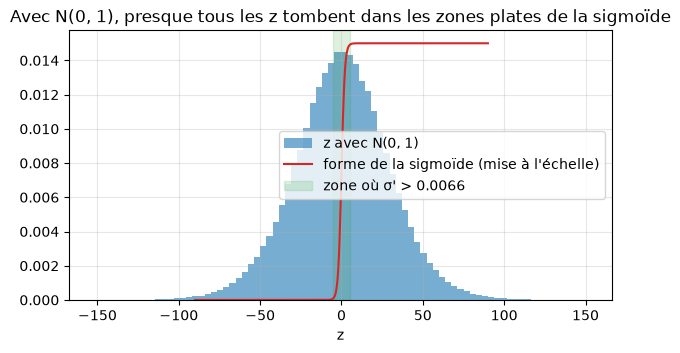

In [38]:
plt.figure(figsize=(7, 3.5))
plt.hist(z_big.flatten().numpy(), bins=80, density=True, alpha=0.6, label="z avec N(0, 1)")
zs = np.linspace(-90, 90, 500)
plt.plot(zs, 1 / (1 + np.exp(-zs)) * 0.015, color="C3", label="forme de la sigmoïde (mise à l'échelle)")
plt.axvspan(-5, 5, color="C2", alpha=0.15, label="zone où σ' > 0.0066")
plt.xlabel("z"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Avec N(0, 1), presque tous les z tombent dans les zones plates de la sigmoïde")
plt.show()

On mesure 29 au lieu de 28 : ces 1000 images ont des pixels de variance un peu supérieure à 1, et on n'a tiré qu'un seul jeu de poids. L'ordre de grandeur est le bon, et 86 % des $z$ tombent dans les zones plates de la sigmoïde, comme prévu.

> ✅ **À retenir (exercice du cours 3)**
>
> - Des poids tous égaux ne brisent pas la symétrie : initialiser **au hasard**, centré sur 0.
> - $\text{Var}(z) = n_\text{in}\,\text{Var}(w)\,\text{Var}(x)$ : pour garder la taille du signal, $\text{Var}(w) \approx 1/n_\text{in}$.
> - Pour `nn.Linear(784, 256)` : Xavier 0.0439 (ou 0.0357), He 0.0505. Avec $\mathcal{N}(0, 1)$, $z$ a un écart-type de 28 et la sigmoïde sature.
> - **He** ($2/n_\text{in}$) pour ReLU, **Xavier** pour tanh et sigmoïde.

---
# Partie D : l'initialisation (TP, exercices 17 à 19)

Les fonctions de `nn.init` remplissent un tenseur **en place** (le `_` final) avec des valeurs aléatoires :

| fonction | distribution | variance |
|---|---|---|
| `nn.init.zeros_(w)` | que des zéros | 0 |
| `nn.init.normal_(w, mean=0.0, std=s)` | $\mathcal{N}(0, s^2)$ | $s^2$ |
| `nn.init.xavier_normal_(w)` | Xavier / Glorot | $2 / (n_\text{in} + n_\text{out})$ |
| `nn.init.kaiming_normal_(w, nonlinearity="relu")` | He / Kaiming | $2 / n_\text{in}$ |

(`xavier_uniform_` et `kaiming_uniform_` donnent les mêmes variances avec une loi uniforme.)

## Exercice TP 17 : une fonction d'initialisation

> **Énoncé** : compléter `init_weights(model, kind)` : pour chaque `nn.Linear` du modèle, remplir le poids selon `kind` (`"zeros"`, `"small"` = $\mathcal{N}(0, 0.01^2)$, `"large"` = $\mathcal{N}(0, 1)$, `"xavier"`, `"he"`) et mettre le biais à zéro. Renvoyer le modèle.

📖 **Pièges à éviter**

- L'argument `std` de `normal_` est l'**écart-type** (0.01), pas la variance ($0.01^2 = 0.0001$).
- `kaiming_normal_` utilise par défaut `mode="fan_in"`, c'est-à-dire $n_\text{in}$ (le nombre d'entrées de la couche), comme dans la formule de He. Il faut préciser `nonlinearity="relu"` pour avoir le gain $\sqrt{2}$.
- Le `raise ValueError` final protège contre une faute de frappe dans `kind` : sans lui, la couche garderait silencieusement son initialisation par défaut.

In [39]:
def init_weights(model, kind):
    for m in model:
        if isinstance(m, nn.Linear):
            ### START CODE HERE ###
            if kind == "zeros":
                nn.init.zeros_(m.weight)
            elif kind == "small":
                nn.init.normal_(m.weight, mean=0.0, std=0.01)               # std 0.01, donc variance 0.01^2
            elif kind == "large":
                nn.init.normal_(m.weight, mean=0.0, std=1.0)
            elif kind == "xavier":
                nn.init.xavier_normal_(m.weight)                            # variance 2 / (n_in + n_out)
            elif kind == "he":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")      # variance 2 / n_in
            else:
                raise ValueError(f"initialisation inconnue : {kind}")
            nn.init.zeros_(m.bias)                                          # biais à zéro dans tous les cas
            ### END CODE HERE ###
    return model


torch.manual_seed(0)
probe = init_weights(nn.Sequential(nn.Linear(784, 256)), "he")
print(f"He: std of the weights {probe[0].weight.std().item():.4f} (theory sqrt(2/784) = {math.sqrt(2 / 784):.4f})")
assert abs(probe[0].weight.std().item() - math.sqrt(2 / 784)) < 0.002, "he: std should be sqrt(2 / n_in)"
assert probe[0].bias.abs().sum().item() == 0, "biases should be set to zero"
small = init_weights(nn.Sequential(nn.Linear(784, 256)), "small")[0].weight.std().item()
xav = init_weights(nn.Sequential(nn.Linear(784, 256)), "xavier")[0].weight.std().item()
assert abs(small - 0.01) < 0.001 and abs(xav - math.sqrt(2 / (784 + 256))) < 0.002, "check 'small' and 'xavier'"
assert init_weights(nn.Sequential(nn.Linear(784, 256)), "zeros")[0].weight.abs().sum().item() == 0, "check 'zeros'"
print("Exercise validated!")

He: std of the weights 0.0506 (theory sqrt(2/784) = 0.0505)


Exercise validated!


## Exercice TP 18 : le signal à travers une pile ReLU profonde (livrable)

> **Énoncé** : compléter `activation_stds(model, x)` : faire passer `x` à travers les couches **une par une** (`for m in model: x = m(x)`) dans `torch.no_grad()`, et après chaque `nn.ReLU`, ajouter `x.std().item()` à la liste `stds`. La boucle construit ensuite une pile de 10 couches cachées ReLU de 256 neurones avec chaque initialisation, et enregistre l'écart-type des activations de chaque couche sur 1000 images.

📖 On fait le forward **à la main**, couche par couche, pour pouvoir regarder ce qui sort de chaque couche. `torch.no_grad()` : on ne fait que mesurer, pas besoin de graphe.

✍️ **Prévision avec l'argument de variance.** Pour une couche ReLU $256 \to 256$, l'écart-type est multiplié à chaque couche par $\sqrt{n_\text{in}\,\text{Var}(w) / 2}$ (le $/2$ vient de la ReLU) :

| init | $\text{Var}(w)$ | facteur par couche $\sqrt{256 \times \text{Var}(w) / 2}$ | après 9 couches de plus |
|---|---|---|---|
| zeros | 0 | 0 | tout vaut 0 |
| small | $0.01^2$ | $\sqrt{256 \times 0.0001 / 2} \approx 0.11$ | $0.11^9 \approx 3 \times 10^{-9}$ : **disparaît** |
| large | 1 | $\sqrt{256/2} \approx 11.3$ | $11.3^9 \approx 3 \times 10^{9}$ : **explose** |
| xavier | $2/512 = 1/256$ | $\sqrt{1/2} \approx 0.71$ | $0.71^9 \approx 0.04$ : baisse lentement |
| he | $2/256$ | $\sqrt{1} = 1$ | **constant** |

(La première couche a $n_\text{in} = 784$, son facteur est un peu différent ; c'est la **répétition** du même facteur sur 10 couches qui fait tout.)

In [40]:
def activation_stds(model, x):
    stds = []
    ### START CODE HERE ###
    with torch.no_grad():
        for m in model:                    # le forward à la main, couche par couche
            x = m(x)
            if isinstance(m, nn.ReLU):     # après chaque activation, on mesure
                stds.append(x.std().item())
    ### END CODE HERE ###
    return stds


x_probe = X_train[:1000].to(device)
stds_by_init = {}
for kind in ["zeros", "small", "large", "xavier", "he"]:
    torch.manual_seed(0)
    stack = init_weights(make_mlp(10, nn.ReLU, width=256), kind).to(device)
    stds_by_init[kind] = activation_stds(stack, x_probe)
    print(f"{kind:7s}", " ".join("%.1e" % v for v in stds_by_init[kind]))

he = stds_by_init["he"]
assert len(he) == 10, "one std per hidden layer (10)"
assert max(stds_by_init["zeros"]) == 0, "zeros: every activation is 0"
assert stds_by_init["small"][-1] < 1e-6 and stds_by_init["large"][-1] > 1e6, "small vanishes, large explodes"
assert 0.5 < he[-1] / he[0] < 2, "He should keep the std roughly constant from layer 1 to layer 10"
print("Exercise validated!")

zeros   0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
small   1.6e-01 1.8e-02 2.2e-03 2.5e-04 2.5e-05 3.0e-06 3.0e-07 3.2e-08 3.8e-09 4.3e-10
large   1.6e+01 1.8e+02 2.2e+03 2.5e+04 2.5e+05 3.0e+06 3.0e+07 3.2e+08 3.8e+09 4.3e+10


xavier  7.2e-01 5.0e-01 3.8e-01 2.7e-01 1.7e-01 1.3e-01 7.9e-02 5.2e-02 3.9e-02 2.8e-02
he      8.2e-01 8.1e-01 8.9e-01 8.7e-01 7.8e-01 8.2e-01 7.2e-01 6.7e-01 7.1e-01 7.2e-01
Exercise validated!


Helper du TP (à exécuter) : l'écart-type des activations, couche par couche (échelle logarithmique ; `zeros` n'est pas tracé car $\log 0$ n'est pas défini). C'est le **graphique livrable** de l'exercice 18.

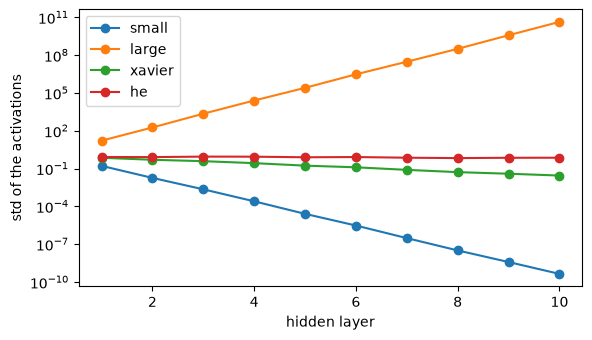

In [41]:
plt.figure(figsize=(6.5, 3.6))
for kind in ["small", "large", "xavier", "he"]:
    plt.plot(range(1, 11), stds_by_init[kind], "o-", label=kind)
plt.yscale("log"); plt.xlabel("hidden layer"); plt.ylabel("std of the activations"); plt.legend(); plt.show()

small   facteur mesuré par couche   0.112   théorie   0.113
large   facteur mesuré par couche  11.157   théorie  11.314
xavier  facteur mesuré par couche   0.697   théorie   0.707
he      facteur mesuré par couche   0.986   théorie   1.000
défaut  facteur mesuré par couche   0.410   théorie   0.408


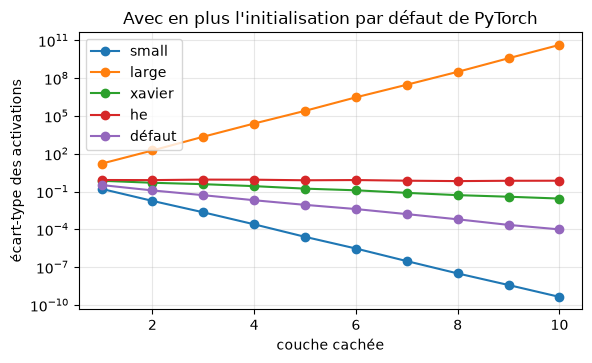

In [42]:
# Le facteur mesuré par couche (entre les couches 2 et 10, toutes en 256 -> 256), comparé à la théorie
theorie = {"small": math.sqrt(256 * 0.01 ** 2 / 2), "large": math.sqrt(256 / 2),
           "xavier": math.sqrt(256 * (2 / 512) / 2), "he": 1.0, "défaut": math.sqrt(256 / (3 * 256) / 2)}
torch.manual_seed(0)
stack_defaut = make_mlp(10, nn.ReLU, width=256).to(device)    # poids : l'initialisation par défaut de PyTorch...
for m in stack_defaut:
    if isinstance(m, nn.Linear):
        nn.init.zeros_(m.bias)                                # ... et biais nuls, comme pour les autres
stds_by_init["défaut"] = activation_stds(stack_defaut, x_probe)
for kind in ["small", "large", "xavier", "he", "défaut"]:
    st = stds_by_init[kind]
    facteur = (st[-1] / st[1]) ** (1 / 8)       # moyenne géométrique des 8 facteurs entre les couches 2 et 10
    print(f"{kind:7s} facteur mesuré par couche {facteur:7.3f}   théorie {theorie[kind]:7.3f}")

plt.figure(figsize=(6.5, 3.6))
for kind in ["small", "large", "xavier", "he", "défaut"]:
    plt.plot(range(1, 11), stds_by_init[kind], "o-", label=kind)
plt.yscale("log"); plt.xlabel("couche cachée"); plt.ylabel("écart-type des activations"); plt.legend()
plt.title("Avec en plus l'initialisation par défaut de PyTorch"); plt.grid(alpha=0.3); plt.show()

💡 **Ce qu'on observe.** Les mesures collent à la prévision : un facteur de 0.112 par couche avec `small` (théorie 0.113), 11.2 avec `large` (11.3), 0.70 avec Xavier (0.71) et 0.99 avec He (1). Après 10 couches : $4 \times 10^{-10}$ pour `small` et $4 \times 10^{10}$ pour `large`, les nombres de la slide 20.

- **small** : chaque couche multiplie le signal par environ 0.11 ; après 10 couches, il ne reste rien. Les gradients disparaissent de la même façon.
- **large** : environ 11 par couche, le signal **explose**.
- **xavier** : conçue pour tanh et la sigmoïde ; avec ReLU, elle perd un facteur $\sqrt{2}$ par couche (la ReLU met la moitié du signal à zéro), d'où une baisse lente.
- **he** : compense exactement ce facteur 2, l'écart-type reste **constant**.
- **zeros** : tout vaut 0 et, pire, tous les neurones d'une couche sont identiques et le restent (l'argument de symétrie).
- **défaut de PyTorch** (bonus, avec des biais nuls pour comparer à armes égales) : $\text{Var}(w) = 1/(3\,n_\text{in})$, donc un facteur $\sqrt{256 \times \frac{1}{3 \times 256} / 2} = \sqrt{1/6} \approx 0.41$ par couche. Le signal diminue, mais beaucoup moins vite qu'avec `small` : sur 6 couches, il garde une taille exploitable, et c'est pour ça que le réseau ReLU de la partie C a pu apprendre.

## Exercice TP 19 : est-ce que ça s'entraîne ?

> **Énoncé** : entraîner deux fois le réseau ReLU à 6 couches pendant `EPOCHS` époques, une fois initialisé avec `"small"` et une fois avec `"he"`, avec SGD et `lr=0.05`. Stocker les précisions de validation finales dans `acc_init["small"]` et `acc_init["he"]`.

📖 **Pourquoi `lr=0.05` et pas 0.2 ?** Avec He, les signaux et les gradients sont plus grands qu'avec l'initialisation par défaut ; un pas de 0.2 risquerait de faire diverger l'entraînement (ou de tuer des ReLU, slide 16). On prend un pas plus prudent.

On garde aussi les historiques (`hist_init`, un ajout par rapport au TP) pour tracer les courbes.

In [43]:
acc_init = {}
hist_init = {}                     # (ajout : les historiques, pour le graphique)
for kind in ["small", "he"]:
    ### START CODE HERE ###
    torch.manual_seed(0)
    net = init_weights(make_mlp(6, nn.ReLU), kind).to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=0.05)
    hist_init[kind] = fit(net, train_loader, val_loader, nn.CrossEntropyLoss(), optimizer, EPOCHS, verbose=False)
    acc_init[kind] = hist_init[kind]["val_acc"][-1]
    ### END CODE HERE ###

print(acc_init)
assert set(acc_init) == {"small", "he"}, "one entry for 'small' and one for 'he'"
assert acc_init["small"] < 0.3, "with N(0, 0.01^2) the signal vanishes and the network should not learn"
assert acc_init["he"] > 0.75, f"with He the network should learn, got {acc_init['he']:.3f}"
print("Exercise validated!")

{'small': 0.0947, 'he': 0.8691}
Exercise validated!


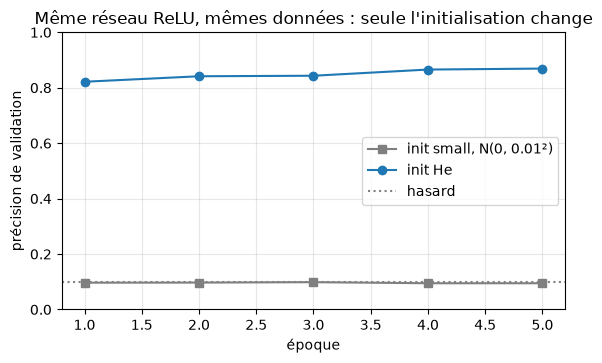

In [44]:
plt.figure(figsize=(6.5, 3.6))
plt.plot(ep, hist_init["small"]["val_acc"], "s-", color="C7", label="init small, N(0, 0.01²)")
plt.plot(ep, hist_init["he"]["val_acc"], "o-", color="C0", label="init He")
plt.axhline(0.1, color="gray", ls=":", label="hasard")
plt.ylim(0, 1); plt.xlabel("époque"); plt.ylabel("précision de validation"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Même réseau ReLU, mêmes données : seule l'initialisation change")
plt.show()

💡 **Ce qu'on observe.** Avec `small`, la précision de validation reste à 9.5 % (le hasard) ; avec He, elle atteint 86.9 % en 5 époques.

Même réseau, mêmes données, même optimiseur : **seuls les poids de départ diffèrent**, et l'un reste au hasard pendant que l'autre apprend. Avec `small`, le signal s'éteint en avant (facteur 0.11 par couche) et le gradient s'éteint en arrière de la même façon : rien ne bouge. Avec He, le signal garde sa taille dans les deux sens.

Le défaut de PyTorch pour `nn.Linear` (utilisé dans les parties A à C) est une loi uniforme de variance $1/(3\,n_\text{in})$ : ni Xavier ni He, mais dans le bon ordre de grandeur. C'est pour ça que le réseau ReLU profond de la partie C a appris, un peu plus lentement.

> ✅ **À retenir (partie D)**
>
> - L'initialisation décide si un réseau profond **peut** apprendre : trop petite, le signal disparaît ; trop grande, il explose.
> - Facteur par couche ReLU : $\sqrt{n_\text{in}\,\text{Var}(w)/2}$. He ($\text{Var}(w) = 2/n_\text{in}$) le met exactement à 1.
> - En PyTorch : `nn.init.kaiming_normal_(w, nonlinearity="relu")` et `nn.init.zeros_(b)`.

---
# Pour aller plus loin : dépasser 88 % (TP, exercice 20)

> **Énoncé** : construire un réseau à 3 couches cachées ReLU (par exemple 256, 128 et 64 neurones), l'initialiser avec He, l'entraîner avec `torch.optim.Adam(model.parameters(), lr=1e-3)` pendant `epochs_gf` époques, et stocker sa précision de test dans `test_acc_gf`. Objectif : environ 0.88 sur le test (l'assert accepte 0.875).

📖 **Les choix, et pourquoi**

- **ReLU** dans les couches cachées : le gradient circule (parties B et C).
- **He** : le signal garde la même taille à travers les couches (partie D). `init_weights` l'applique aussi à la couche de sortie, ce qui ne pose aucun problème.
- **Adam** (détaillé à la session 6) : au lieu d'un seul pas $\eta$ pour tous les paramètres, Adam adapte le pas **de chaque paramètre** à partir de l'historique de ses gradients (une moyenne des gradients et une moyenne de leurs carrés). En pratique, il converge bien plus vite que le SGD simple, avec le réglage standard `lr=1e-3`.
- **Largeurs décroissantes** 256, 128, 64 : on compresse progressivement l'information vers les 10 classes.

✍️ **Nombre de paramètres** :

$$\underbrace{784 \times 256 + 256}_{200\,960} + \underbrace{256 \times 128 + 128}_{32\,896} + \underbrace{128 \times 64 + 64}_{8\,256} + \underbrace{64 \times 10 + 10}_{650} = 242\,762$$

In [45]:
epochs_gf = 4 if FAST_RUN else 12
torch.manual_seed(0)
### START CODE HERE ###
model_gf = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 10),
)
model_gf = init_weights(model_gf, "he").to(device)              # He : adaptée à ReLU
optimizer = torch.optim.Adam(model_gf.parameters(), lr=1e-3)    # Adam : un pas adapté à chaque paramètre
loss_fn = nn.CrossEntropyLoss()
history_gf = fit(model_gf, train_loader, val_loader, loss_fn, optimizer, epochs_gf)
_, test_acc_gf = evaluate(model_gf, test_loader, loss_fn)        # le test, une seule fois, à la fin
### END CODE HERE ###

print(f"test accuracy: {test_acc_gf:.3f} (baseline of Part A: {test_acc:.3f})")
assert test_acc_gf > (0.84 if FAST_RUN else 0.875), "keep tuning: width, epochs, learning rate"
print("Exercise validated!")

epoch  1 | train loss 0.4882 | val loss 0.4060 | val acc 0.847


epoch  2 | train loss 0.3523 | val loss 0.3572 | val acc 0.865


epoch  3 | train loss 0.3173 | val loss 0.3361 | val acc 0.878


epoch  4 | train loss 0.2870 | val loss 0.3263 | val acc 0.881


epoch  5 | train loss 0.2679 | val loss 0.3214 | val acc 0.883


...

epoch  8 | train loss 0.2249 | val loss 0.3393 | val acc 0.877


epoch  9 | train loss 0.2140 | val loss 0.3271 | val acc 0.884


epoch 10 | train loss 0.2047 | val loss 0.3218 | val acc 0.885


epoch 11 | train loss 0.1921 | val loss 0.3220 | val acc 0.891


epoch 12 | train loss 0.1820 | val loss 0.3297 | val acc 0.892
test accuracy: 0.883 (baseline of Part A: 0.858)
Exercise validated!


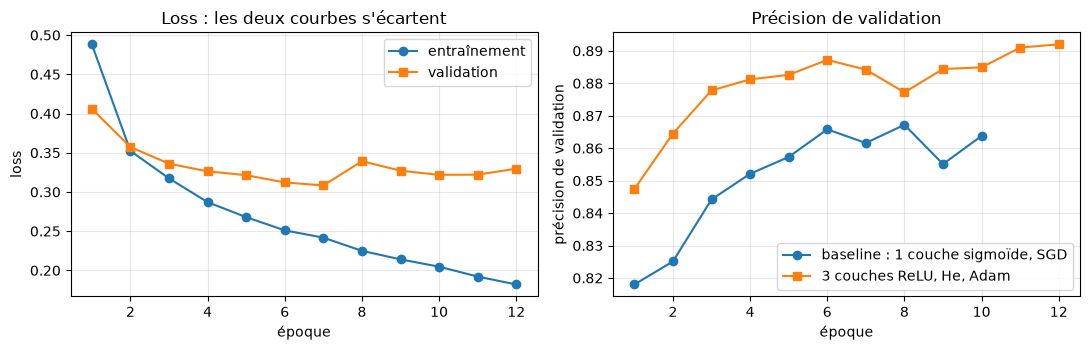

In [46]:
ep_gf = range(1, epochs_gf + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ep_gf, history_gf["train_loss"], "o-", label="entraînement")
axes[0].plot(ep_gf, history_gf["val_loss"], "s-", label="validation")
axes[0].set(xlabel="époque", ylabel="loss", title="Loss : les deux courbes s'écartent")
axes[0].legend()
axes[1].plot(ep_a, history_a["val_acc"], "o-", label="baseline : 1 couche sigmoïde, SGD")
axes[1].plot(ep_gf, history_gf["val_acc"], "s-", label="3 couches ReLU, He, Adam")
axes[1].set(xlabel="époque", ylabel="précision de validation", title="Précision de validation")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

💡 **Ce qu'on observe.** Le réseau ReLU + He + Adam atteint **88.3 %** sur le test, contre 85.8 % pour la baseline de la partie A, avec 89.2 % de précision de validation à la dernière époque. Mais regarde les loss : celle d'entraînement continue de baisser (0.18 à la fin), alors que celle de validation stagne autour de 0.31 à 0.33 depuis la 6e époque.

Cet écart entre loss d'entraînement et loss de validation, c'est le début du **surapprentissage** (overfitting) : le réseau commence à apprendre par cœur ses images d'entraînement. Le combattre (dropout, weight decay, batch normalisation) et bien choisir l'optimiseur (momentum, Adam), c'est le programme de la session 6.

---
# 📝 Livrables et fiche résumé de la session 5

In [47]:
print("LIVRABLES DE LA SESSION 5")
print("\nPartie A :")
print(f"  précision de test de la baseline 784-128-10 : {test_acc:.1%}")
print(f"  erreur la plus fréquente : {CLASSES[true_cls]} prédit {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} fois)")
print("\nExercice 15, le tableau des activations (6 couches cachées de 128, SGD lr 0.2, "
      f"{EPOCHS} époques) :")
print(f"  {'activation':12s} {'gradient 1re / dernière':>24s} {'précision de validation':>25s}")
for name, (r, acc) in results.items():
    print(f"  {name:12s} {r:24.1e} {acc:25.1%}")
print("\nExercice 18 : le graphique des écarts-types des activations (plus haut, partie D)")
print(f"\nPour aller plus loin : 3 couches ReLU + He + Adam, précision de test {test_acc_gf:.1%}")

LIVRABLES DE LA SESSION 5

Partie A :
  précision de test de la baseline 784-128-10 : 85.8%
  erreur la plus fréquente : Pullover prédit Coat (194 fois)

Exercice 15, le tableau des activations (6 couches cachées de 128, SGD lr 0.2, 5 époques) :
  activation    gradient 1re / dernière   précision de validation
  Sigmoid                       4.7e-05                      9.7%
  Tanh                          2.0e+00                     86.8%
  ReLU                          6.7e-01                     86.4%
  LeakyReLU                     6.7e-01                     87.1%

Exercice 18 : le graphique des écarts-types des activations (plus haut, partie D)

Pour aller plus loin : 3 couches ReLU + He + Adam, précision de test 88.3%


| Notion | Formule | En une phrase |
|---|---|---|
| Aplatir une image | $(B, 28, 28) \to (B, 784)$ | une couche dense prend un vecteur ; on perd la structure 2D |
| Standardiser | $x \leftarrow (x - \mu)/s$, $\mu$ et $s$ de l'entraînement | entrées de moyenne 0 et de variance 1, sans fuite de données |
| Loss du hasard | $\ln 10 \approx 2.30$ | 10 classes à $1/10$ chacune : le réseau n'a rien appris |
| Backprop en profondeur | $\dfrac{\partial a^{[L]}}{\partial a^{[0]}} = \prod_l w^{[l]}\,\sigma'(z^{[l]})$ | un facteur par couche |
| Sigmoïde | $\sigma' \le 1/4$ | le gradient disparaît exponentiellement avec la profondeur |
| ReLU | $\max(0, z)$, dérivée 0 ou 1 | le choix par défaut des couches cachées |
| ReLU morte | $z < 0$ pour toutes les entrées | plus aucun gradient ; remèdes : bon pas, init He, Leaky ReLU |
| Symétrie | poids égaux, neurones identiques pour toujours | initialiser au hasard, centré sur 0 |
| Variance | $\text{Var}(z) = n_\text{in}\,\text{Var}(w)\,\text{Var}(x)$ | garder $n_\text{in}\,\text{Var}(w) \approx 1$ |
| Xavier | $1/n_\text{in}$ ou $2/(n_\text{in} + n_\text{out})$ | pour tanh et sigmoïde |
| He | $2/n_\text{in}$ | pour ReLU : le 2 compense la moitié mise à zéro |

**Prochaine session** : d'autres outils contre la même famille de problèmes et contre le surapprentissage : batch normalisation, dropout, weight decay, de meilleurs optimiseurs (momentum, Adam), et comment diagnostiquer un entraînement à partir de ses courbes.